# ¿Cuándo un accidente se convierte en colapso del tráfico? Patrones de accidentes de alto impacto en EE.UU. (2016–2023)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2

**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque

**Tema:** movilidad urbana y patrones de congestión, estudiados a través de los accidentes de tránsito que más alteran el tráfico. Con una muestra de 540 988 accidentes (2016–2023, 49 estados de EE.UU.) describimos cuándo, dónde y bajo qué condiciones se concentran, y evaluamos si los datos son confiables para orientar decisiones de control vial.

**Integrantes:**
    - Charca Condori Yordi Brayan
    - Chura Puma Cristian Erik
    - Condori Quispe Kewin Erick
    - Inofuente Trujillo David Alex
    - Vargas Idme Vladimir Yordanov

### Ruta del trabajo (un solo notebook, arquitectura *medallion*)

| Parte | Capa | Qué hace | Preguntas que responde |
|---|---|---|---|
| **I. Exploración** | Bronze | Pregunta, fuente, carga, perfil descriptivo y diccionario. No limpia ni evalúa reglas | ¿Qué queremos conocer? ¿Qué representa una fila? |
| **II. Calidad y preparación** | Bronze → Silver | 18 reglas en 6 dimensiones, selección de columnas, limpieza y variables derivadas | ¿Qué datos son confiables? ¿Qué transformamos? |
| **III. Análisis y conclusiones** | Silver → Gold | EDA descriptivo, diagnóstico y prescriptivo; conclusiones con sus límites | ¿Qué patrones aparecen? ¿Qué podemos afirmar? |

Cada paso se hace **una sola vez**: la Parte II usa la muestra que cargó la Parte I y la Parte III usa la tabla Silver que creó la Parte II.

> **Para reproducir todos los resultados:** abrir el notebook con el kernel del entorno del proyecto (`pip install -r requirements.txt`) y ejecutar **Kernel → Restart & Run All** (2 a 4 minutos). Funciona desde cualquier carpeta del repositorio. Si el archivo `data/bronze/us_accidents/US_Accidents_March23.csv` no existe, la celda I.0.3 lo descarga de Kaggle (≈ 650 MB comprimido, ≈ 3 GB descomprimido).

---
# PARTE I — Exploración (capa Bronze)

*¿Qué queremos conocer y qué representa cada fila?* En esta parte los datos se describen **tal como llegan**: no se convierten tipos, no se crean variables, no se evalúan reglas ni se elimina nada.

---
## I.0 Preparación reproducible

El notebook sigue la arquitectura *medallion* del repositorio `EDA`:
| Capa | Carpeta | Qué contiene |
|---|---|---|
| **Bronze** | `data/bronze/us_accidents/` | El CSV original de Kaggle, **sin modificar**, y un `manifest.json` con su tamaño y huella SHA-256 |
| **Silver** | `data/silver/us_accidents/` | La tabla limpia y sus metadatos (Parte II) |
| **Gold** | `data/gold/us_accidents/` | Tablas de resultados del análisis (Parte III) |
| **Outputs** | `outputs/us_accidents/` | Gráficos del notebook en PNG |

**Preparar el entorno en otra computadora** (con 3.12)
```bash
py -3.12 -m venv BigData20262
.\BigData20262\Scripts\Activate.ps1      
pip install -r requirements.txt
```
Luego abrir este notebook y elegir como kernel el Python de `BigData20262`.


In [1]:
# Celda I.0.1: localizar la raíz del proyecto y definir las capas de datos
import hashlib
import importlib.util
import json
import os
import platform
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Localiza la raíz del repositorio por sus carpetas data/ y notebooks/."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA (carpetas data/ y notebooks/).")


PROJECT_ROOT = find_project_root(Path.cwd())
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "us_accidents"
SILVER_DIR = PROJECT_ROOT / "data" / "silver" / "us_accidents"
GOLD_DIR = PROJECT_ROOT / "data" / "gold" / "us_accidents"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "us_accidents"

for folder in (BRONZE_DIR, SILVER_DIR, GOLD_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]} ({platform.system()})")
print(f"Bronze   : {BRONZE_DIR.relative_to(PROJECT_ROOT)}")
print(f"Silver   : {SILVER_DIR.relative_to(PROJECT_ROOT)}")
print(f"Gold     : {GOLD_DIR.relative_to(PROJECT_ROOT)}")
print(f"Outputs  : {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Proyecto : C:\Users\Erik\Documents\EDA-TF\EDA-bigdata
Python   : 3.12.10 (Windows)
Bronze   : data\bronze\us_accidents
Silver   : data\silver\us_accidents
Gold     : data\gold\us_accidents
Outputs  : outputs\us_accidents


In [2]:
# Celda I.0.2: verificar dependencias sin modificar el entorno y registrar versiones
REQUERIDAS = ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]   # scipy: correlación de Spearman (Parte III)   # kaggle solo se exige si hay que descargar (0.3)
faltantes = [lib for lib in REQUERIDAS if importlib.util.find_spec(lib) is None]
if faltantes:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(faltantes) +
        ". Ejecute desde la raíz del proyecto: python -m pip install -r requirements.txt"
    )

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#c3c2b7", "axes.titlesize": 12})


def guardar_figura(fig, nombre: str) -> None:
    """Guarda cada gráfico en outputs/us_accidents/ para el informe."""
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")


print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", matplotlib.__version__)

pandas    : 3.1.0
numpy     : 2.5.4
matplotlib: 3.11.2


### I.0.3 Obtención del dataset (capa Bronze)
La celda es **idempotente**: si el CSV ya está en Bronze no lo vuelve a descargar (salvo `FORCE_DOWNLOAD = True`). Luego registra en `manifest.json` el tamaño y la huella SHA-256 del archivo, para comprobar que todos trabajan con **el mismo archivo original**.

In [3]:
# Celda I.0.3: descargar el CSV original en Bronze (solo si falta) y registrar su huella
DATASET_SLUG = "sobhanmoosavi/us-accidents"
ARCHIVO = "US_Accidents_March23.csv"
TAMANO_ESPERADO = 3_058_183_727          # bytes, según Kaggle (versión de marzo 2023)
RUTA = BRONZE_DIR / ARCHIVO
FORCE_DOWNLOAD = False

if FORCE_DOWNLOAD or not RUTA.is_file():
    kaggle_dir = Path(os.environ.get("KAGGLE_CONFIG_DIR", Path.home() / ".kaggle"))
    token_en_entorno = "KAGGLE_API_TOKEN" in os.environ or {"KAGGLE_USERNAME", "KAGGLE_KEY"} <= os.environ.keys()
    token_en_archivo = (kaggle_dir / "access_token").is_file() or (kaggle_dir / "kaggle.json").is_file()
    if not (token_en_entorno or token_en_archivo):
        raise FileNotFoundError(
            f"No se encontró {ARCHIVO} en {BRONZE_DIR.relative_to(PROJECT_ROOT)} ni un token de Kaggle en {kaggle_dir}. "
            "Configure el token (ver sección I.0) o coloque el CSV manualmente en esa carpeta."
        )
    if importlib.util.find_spec("kaggle") is None:
        raise ModuleNotFoundError("Para descargar el dataset falta la librería kaggle: python -m pip install -r requirements.txt")
    print("Descargando desde Kaggle (≈ 650 MB, puede tardar varios minutos)...")
    subprocess.run([sys.executable, "-m", "kaggle", "datasets", "download",
                    "-d", DATASET_SLUG, "--unzip", "-p", str(BRONZE_DIR)], check=True)

if not RUTA.is_file():
    raise FileNotFoundError(f"La descarga no produjo el archivo esperado: {RUTA}")
if RUTA.stat().st_size != TAMANO_ESPERADO:
    print(f"⚠️ El tamaño ({RUTA.stat().st_size:,} bytes) no coincide con la versión de Kaggle "
          f"({TAMANO_ESPERADO:,} bytes): los resultados pueden diferir.")


def sha256(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


archivos = [{"name": RUTA.name, "bytes": RUTA.stat().st_size, "sha256": sha256(RUTA)}]
ruta_manifest = BRONZE_DIR / "manifest.json"
manifest = json.loads(ruta_manifest.read_text(encoding="utf-8")) if ruta_manifest.is_file() else {}
# Solo se reescribe si el archivo cambió: así la fecha de ingesta no se modifica en cada ejecución
if manifest.get("files") != archivos:
    manifest = {
        "dataset": DATASET_SLUG,
        "source_url": f"https://www.kaggle.com/datasets/{DATASET_SLUG}",
        "license": "CC BY-NC-SA 4.0",
        "ingested_at_utc": datetime.now(timezone.utc).isoformat(),
        "layer": "bronze",
        "files": archivos,
    }
    ruta_manifest.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print("Bronze listo (dato original, sin transformación):")
for entry in manifest["files"]:
    print(f"  {entry['name']}  {entry['bytes'] / 1024**3:.2f} GB  SHA-256 {entry['sha256'][:12]}…")

Bronze listo (dato original, sin transformación):
  US_Accidents_March23.csv  2.85 GB  SHA-256 e3e9f962e3e2…


---
## I.1 Proyecto, tema e integrantes

### I.1.1 Ficha del proyecto
- **Nombre del proyecto:** ¿Cuándo un accidente se convierte en colapso del tráfico?
- **Tema:** movilidad urbana y patrones de congestión, estudiados a través de los **accidentes de tránsito que más alteran el tráfico**. Con una muestra de **540 988 accidentes** (2016–2023, 49 estados de EE.UU.) describimos cuándo, dónde y bajo qué condiciones se concentran, y evaluamos si los datos son confiables para orientar decisiones de control vial.
- **¿Por qué es un caso de Big Data?** Por su **volumen** (~7,7 millones de registros y ~3 GB), su **variedad** (tiempo, ubicación, clima e infraestructura en una misma tabla) y porque combina **varias fuentes** de datos de tráfico que no registran la información de la misma forma.


### I.1.2 Accidentes y tráfico (glosario)

| Término | Qué significa en este trabajo |
|---|---|
| **Severidad** (`Severity`) | Escala de 1 a 4 que mide **cuánto afecta el accidente al tráfico** (por ejemplo, cuánto retraso genera). **No** mide la gravedad de las lesiones. 1 = impacto bajo, 4 = impacto alto. |
| **Accidente de alto impacto** | En este trabajo, un accidente de **severidad 3 o 4**: es el que convierte un incidente en **colapso del tráfico**. |
| **Fuente** (`Source`) | Proveedor de datos de tráfico que reportó el accidente. Hay tres: Source1, Source2 y Source3. Cada una recoge la información a partir de departamentos de transporte, policía, cámaras y sensores. |
| **Tramo afectado** (`Distance(mi)`) | Longitud de vía afectada por el accidente. |
| **Hora local** | `Start_Time` está en la hora de la zona donde ocurrió el accidente (`Timezone`). EE.UU. tiene 4 zonas horarias continentales. |
| **Elementos de la vía** | Variables Verdadero/Falso que indican si cerca del accidente hay semáforo, cruce peatonal, rampa o salida de autopista (`Junction`), señal de pare o rotonda. Se asignan si el mapa de OpenStreetMap tiene uno a menos de 30 m del accidente (100 m para `Junction`). |

**Unidades de medida (sistema estadounidense) y su equivalencia:**

| Unidad | Equivalencia | Columna |
|---|---|---|
| milla (mi) | 1 mi ≈ 1,61 km | `Distance(mi)`, `Visibility(mi)` |
| grado Fahrenheit (°F) | °C = (°F − 32) × 5/9; 32 °F = 0 °C | `Temperature(F)` |
| pulgada (in) | 1 in = 2,54 cm | `Precipitation(in)` |
| pulgada de mercurio (inHg) | presión normal ≈ 29,9 inHg (1013 hPa) | `Pressure(in)` |
| millas por hora (mph) | 1 mph ≈ 1,61 km/h | `Wind_Speed(mph)` |

---
## I.2 Pregunta motivadora y utilidad esperada

> ### ¿Cuándo, dónde y bajo qué condiciones un accidente deja de ser un incidente aislado y se convierte en un colapso del tráfico?

Cada accidente bloquea vías, retrasa ambulancias y genera congestión que afecta a miles de personas que no estuvieron involucradas. Sin embargo, los recursos de control vial suelen distribuirse de forma uniforme, sin considerar **cuándo y dónde** el riesgo es realmente mayor.

| | |
|---|---|
| **¿Qué queremos describir?** | Los patrones de hora, día, clima y tipo de vía en que se concentran los accidentes de mayor impacto en el tráfico (severidad 3–4). |
| **¿Qué decisión mejora?** | La asignación de patrullaje, semaforización y servicios de emergencia por franja horaria y zona. |
| **¿Quién se beneficia?** | Departamentos de transporte (usuario principal), policía de tránsito y servicios de emergencia. |
| **Tipo de propósito** | Mejorar una decisión. |

**Sub-preguntas que guiarán el análisis** (todas descriptivas, sin afirmar causalidad):

| # | Sub-pregunta | Variables | Dimensión |
|---|---|---|---|
| 1 | ¿En qué horas y días se concentran los accidentes de alto impacto? | `Start_Time`, `Severity` | Tiempo |
| 2 | ¿En qué estados y ciudades se concentran? | `State`, `City`, `Start_Lat`, `Start_Lng` | Lugar |
| 3 | ¿Bajo qué condiciones climáticas aumenta la proporción de alto impacto? | `Weather_Condition`, `Visibility(mi)`, `Precipitation(in)` | Clima |
| 4 | ¿Qué elementos de la vía acompañan a los accidentes de alto impacto? | `Traffic_Signal`, `Crossing`, `Junction`, `Stop`, `Roundabout` | Infraestructura |


---
## I.3 Fuente, período y condiciones de uso

### I.3.1 Ficha de la fuente

| Campo | Valor |
|---|---|
| Dataset | *US Accidents (2016–2023)* — Kaggle: `kaggle.com/datasets/sobhanmoosavi/us-accidents` |
| Autor / mantenedor | Sobhan Moosavi |
| Origen de los datos | APIs de tráfico que transmiten incidentes reportados por departamentos de transporte, policía, cámaras y sensores viales |
| Período | Febrero 2016 – Marzo 2023 |
| Cobertura | 49 estados de EE.UU. continental |
| Tamaño original | ~7,7 millones de registros, 46 columnas (~3 GB en CSV) |
| Archivos del dataset | Un único archivo: `US_Accidents_March23.csv` (3 058 183 727 bytes) |
| Ubicación en el proyecto | `data/bronze/us_accidents/US_Accidents_March23.csv` (descargado por la celda I.0.3) |
| Fecha de la versión | 28-may-2023 (última actualización publicada en Kaggle) |
| Licencia / condiciones de uso | CC BY-NC-SA 4.0: uso no comercial, citando a los autores |
| Citas solicitadas por el autor | Moosavi et al. (2019a). *A Countrywide Traffic Accident Dataset*. arXiv:1906.05409 · Moosavi et al. (2019b). *Accident Risk Prediction based on Heterogeneous Sparse Data*. ACM SIGSPATIAL |

### I.3.2 Alcance: qué se carga y por qué

| Decisión | Justificación |
|---|---|
| **Se cargan 29 de las 46 columnas** | Se eligieron las columnas de tiempo, lugar, severidad, clima y vía (las que usa la pregunta) y las necesarias para evaluar calidad (`ID`, `Source`, `End_Time`, `End_Lat`, `Weather_Timestamp`). |
| **Columnas excluidas** | Texto libre (`Description`, `Street`), columnas redundantes con otras (`County`, `Airport_Code`, `Wind_Chill(F)`, `Wind_Direction`, `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight`) y elementos de la vía muy poco frecuentes (`Amenity`, `Bump`, `Give_Way`, `No_Exit`, `Railway`, `Station`, `Traffic_Calming`, `Turning_Loop`). |
| **Muestra aleatoria del 7 %** (~541 000 filas) | El archivo completo ocupa varios GB en memoria y no es manejable en una computadora personal. Un 7 % aleatorio conserva la distribución del total y sigue siendo una muestra muy grande. |
| **Lectura por bloques de 500 000 filas** | Evita cargar los 3 GB de una sola vez: se toma el 7 % de cada bloque y luego se unen. |
| **Semilla fija** (`random_state=42`) | Garantiza que cualquier persona que ejecute el notebook obtenga **exactamente la misma muestra** y los mismos resultados. |

---
## I.4 Unidad de análisis

**Cada fila representa un accidente de tránsito reportado.** Contiene:
- **cuándo** ocurrió (`Start_Time`, `End_Time`),
- **dónde** (coordenadas, ciudad, estado),
- **el clima** en ese momento (temperatura, visibilidad, lluvia, viento),
- **los elementos de la vía** cercanos (semáforo, cruce, pare, etc.),
- y su **severidad (1 a 4)**, que mide el impacto del accidente en el tráfico.

| Elemento | Valor |
|---|---|
| Unidad de análisis | El accidente reportado |
| Clave (identificador único) | `ID` (su unicidad se verifica en la Parte II) |
| Variable objetivo de la pregunta | `Severity` (alto impacto = 3 o 4) |
| Variable de control | `Source` (las fuentes podrían registrar distinto; se evalúa en la Parte II) |


---
## I.5 Carga reproducible y evidencia básica

In [4]:
# Celda I.5.1: carga reproducible por bloques con una muestra aleatoria fija
COLUMNAS = ["ID","Source","Severity","Start_Time","End_Time",
            "Start_Lat","Start_Lng","End_Lat","End_Lng","Distance(mi)",
            "City","State","Zipcode","Country","Timezone",
            "Weather_Timestamp","Temperature(F)","Humidity(%)","Pressure(in)",
            "Visibility(mi)","Wind_Speed(mph)","Precipitation(in)","Weather_Condition",
            "Traffic_Signal","Crossing","Junction","Stop","Roundabout","Sunrise_Sunset"]
FRACCION, SEMILLA = 0.07, 42
TAMANO_BLOQUE = 500_000

t0 = time.perf_counter()
partes, filas_originales = [], 0
# Zipcode se lee como texto: mezcla códigos de 5 dígitos con códigos extendidos ("12345-6789")
for bloque in pd.read_csv(RUTA, usecols=COLUMNAS, dtype={"Zipcode": str}, chunksize=TAMANO_BLOQUE):
    filas_originales += len(bloque)
    partes.append(bloque.sample(frac=FRACCION, random_state=SEMILLA))
df = pd.concat(partes, ignore_index=True)

print(f"Carga completada en {time.perf_counter() - t0:.0f} s")
print(f"Filas del archivo original : {filas_originales:,}")
print(f"Filas de la muestra ({FRACCION:.0%})  : {len(df):,}")

Carga completada en 28 s
Filas del archivo original : 7,728,394
Filas de la muestra (7%)  : 540,988


In [5]:
# Celda I.5.2: primeras filas
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),City,State,Zipcode,Country,Timezone,Weather_Timestamp,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Crossing,Junction,Roundabout,Stop,Traffic_Signal,Sunrise_Sunset
0,A-104248,Source2,2,2016-04-25 17:18:11,2016-04-25 18:18:11,33.939304,-117.218231,NaN,NaN,0.01,Moreno Valley,CA,92553,US,US/Pacific,2016-04-25 16:58:00,63.9,29.0,29.80,10.0,11.5,NaN,Clear,False,False,False,False,False,Day
1,A-199683,Source2,2,2017-01-10 09:40:16,2017-01-10 10:10:02,42.549671,-71.847313,NaN,NaN,0.01,Fitchburg,MA,01420,US,US/Eastern,2017-01-10 09:52:00,19.0,71.0,30.66,10.0,3.5,NaN,Clear,False,False,False,False,False,Day
2,A-140206,Source2,3,2016-09-02 17:27:56,2016-09-02 18:27:56,26.203491,-80.143852,NaN,NaN,0.00,Fort Lauderdale,FL,33334,US,US/Eastern,2016-09-02 17:53:00,91.0,48.0,29.99,10.0,12.7,NaN,Clear,False,False,False,False,False,Day
3,A-132821,Source2,2,2016-09-29 18:07:37,2016-09-29 18:51:28,27.440348,-82.575432,NaN,NaN,0.00,Bradenton,FL,34207-3610,US,US/Eastern,2016-09-29 18:05:00,77.0,88.0,30.02,1.5,3.5,0.08,Heavy Thunderstorms and Rain,False,False,False,False,True,Day
4,A-408710,Source2,3,2017-05-03 12:12:18,2017-05-03 12:44:00,33.901752,-118.370316,NaN,NaN,0.01,Hawthorne,CA,90250,US,US/Pacific,2017-05-03 11:53:00,72.0,61.0,29.96,10.0,8.1,NaN,Clear,False,False,False,False,False,Day


In [6]:
# Celda I.5.3: dimensiones de la muestra (filas, columnas)
df.shape

(540988, 29)

In [7]:
# Celda I.5.4: tipos de dato, nulos y memoria
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 540988 entries, 0 to 540987
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 540988 non-null  str    
 1   Source             540988 non-null  str    
 2   Severity           540988 non-null  int64  
 3   Start_Time         540988 non-null  str    
 4   End_Time           540988 non-null  str    
 5   Start_Lat          540988 non-null  float64
 6   Start_Lng          540988 non-null  float64
 7   End_Lat            302822 non-null  float64
 8   End_Lng            302822 non-null  float64
 9   Distance(mi)       540988 non-null  float64
 10  City               540969 non-null  str    
 11  State              540988 non-null  str    
 12  Zipcode            540862 non-null  str    
 13  Country            540988 non-null  str    
 14  Timezone           540446 non-null  str    
 15  Weather_Timestamp  532555 non-null  str    
 16  Temperature(F

**Interpretación de la carga**

- La muestra contiene **540 988 accidentes y 29 columnas**, y ocupa ~414 MB en memoria (medido con `memory_usage="deep"`) frente a ~3 GB en disco.
- **Tipos que llegaron mal:** `Start_Time`, `End_Time` y `Weather_Timestamp` llegan como **texto**, no como fecha; se convierten en la Parte II (aquí se exploran tal como vienen). `Severity` es entera, las coordenadas y variables climáticas son decimales, y las variables de la vía son booleanas (Verdadero/Falso).
- **Columnas completas (0 nulos):** `ID`, `Source`, `Severity`, `Start_Time`, `End_Time`, `Start_Lat`, `Start_Lng`, `Distance(mi)`, `State` y los elementos de la vía. Es decir, **las variables centrales de la pregunta (cuándo, dónde, qué severidad y qué tipo de vía) están completas**.
- **Columnas con nulos** (la Parte II decide qué columnas se usan con la regla de máximo 3 % de nulos):

| Columna | Nulos | % |
|---|---|---|
| `End_Lat` / `End_Lng` | 238 166 | 44,02 % |
| `Precipitation(in)` | 154 617 | 28,58 % |
| `Wind_Speed(mph)` | 39 968 | 7,39 % |
| `Visibility(mi)` | 12 456 | 2,30 % |
| `Weather_Condition` | 12 232 | 2,26 % |
| `Temperature(F)` | 11 505 | 2,13 % |
| `Weather_Timestamp` | 8 433 | 1,56 % |

- **Consecuencia:** se puede describir el **cuándo y el dónde** sin pérdidas, pero el análisis por **clima** tendrá faltantes que hay que controlar.

---
## I.6 Perfil descriptivo

Se describen las columnas **tal como llegan de Bronze**. Los valores extraños que aparezcan se anotan como observaciones; las reglas de calidad y sus tratamientos se aplican en la Parte II.

### I.6.1 Variables numéricas: `describe()` explicado
Además de los cuartiles, se agregan los **percentiles 1 % y 99 %**: si el máximo o el mínimo están muy lejos de ellos, hay valores extremos que revisar.

In [8]:
cols_num = ["Severity", "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)",
            "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
perfil_num = df[cols_num].describe(percentiles=[.01, .25, .5, .75, .99]).T
perfil_num["asimetria"] = df[cols_num].skew()
perfil_num.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria
Severity,540988.0,2.21,0.49,1.00,2.00,2.00,2.00,2.00,4.00,4.00,1.82
Start_Lat,540988.0,36.21,5.07,24.56,25.73,33.41,35.83,40.09,47.47,49.00,-0.07
Start_Lng,540988.0,-94.71,17.39,-124.55,-122.97,-117.22,-87.76,-80.36,-71.49,-67.55,-0.48
End_Lat,302822.0,36.27,5.27,24.57,25.69,33.46,36.20,40.19,47.28,49.00,-0.16
End_Lng,302822.0,-95.74,18.11,-124.55,-123.20,-117.76,-88.03,-80.25,-72.88,-67.71,-0.36
Distance(mi),540988.0,0.56,1.81,0.00,0.00,0.00,0.03,0.46,7.00,333.63,26.51
Temperature(F),529483.0,61.66,19.01,-89.00,12.00,49.00,64.00,76.00,96.00,172.00,-0.51
Humidity(%),528755.0,64.85,22.81,1.00,12.00,48.00,67.00,84.00,100.00,100.00,-0.40
Pressure(in),531162.0,29.54,1.00,0.30,24.60,29.37,29.86,30.03,30.44,39.45,-3.72
Visibility(mi),528532.0,9.09,2.70,0.00,0.50,10.00,10.00,10.00,10.00,100.00,2.42


**Interpretación de las variables numéricas** (dato → significado → consecuencia)

- **Severity:** media 2,21 y mediana 2 → la mayoría de accidentes son de impacto moderado → los de alto impacto (3–4) son el grupo minoritario que interesa.
- **Start_Lat / Start_Lng:** latitudes entre 24,56 y 49,00 y longitudes entre −124,55 y −67,55 → todas caen dentro de EE.UU. continental → la ubicación es **válida**.
- **Distance(mi):** mediana de solo 0,03 millas y al menos el 25 % con distancia **0**, pero el máximo llega a **333,63 millas** → distribución muy sesgada → podría ser un valor por defecto (se revisa en la Parte II).
- **Temperature(F):** mínimo **−89 °F** (−67 °C) y máximo **172 °F** (78 °C) → valores físicamente imposibles en EE.UU. → probables errores del sensor.
- **Pressure(in):** mínimo **0,30 inHg** y máximo **39,45 inHg**, cuando la presión normal ronda 29,9 → probables errores de registro. El percentil 1 % es **24,6** porque se trata de **presión de estación** (sin corregir al nivel del mar): en ciudades altas como Denver (~1 600 m) la presión es naturalmente menor, así que **no** es un error.
- **Wind_Speed(mph):** máximo de **243 mph** (391 km/h), más que un huracán extremo → valor atípico.
- **Visibility(mi):** los percentiles 25, 50 y 75 valen exactamente **10** → 10 millas parece ser el **valor máximo que reporta el sensor**, no una medición exacta → la visibilidad solo distingue bien los casos de visibilidad **reducida**.
- **Humidity(%):** entre 1 y 100 → rango válido.
- **Precipitation(in):** solo 386 371 valores (28,58 % nulos) y la mayoría son 0 → es la variable climática **menos confiable**.

### I.6.2 Variables categóricas: ¿cuántas categorías hay y cuál domina?

In [9]:
cols_cat = ["ID", "Source", "City", "State", "Zipcode", "Country", "Timezone",
            "Weather_Condition", "Sunrise_Sunset"]
perfil_cat = pd.DataFrame({
    "no_nulos": df[cols_cat].notna().sum(),
    "categorias": df[cols_cat].nunique(),
    "mas_frecuente": [df[c].value_counts().index[0] for c in cols_cat],
    "frecuencia": [df[c].value_counts().iloc[0] for c in cols_cat],
})
perfil_cat["% del total"] = (perfil_cat["frecuencia"] / len(df) * 100).round(2)
perfil_cat

,no_nulos,categorias,mas_frecuente,frecuencia,% del total
ID,540988,540988,A-104248,1,0.00
Source,540988,3,Source1,302822,55.98
City,540969,9667,Miami,12915,2.39
State,540988,49,CA,121832,22.52
Zipcode,540862,136468,91761,787,0.15
Country,540988,1,US,540988,100.00
Timezone,540446,4,US/Eastern,250575,46.32
Weather_Condition,528756,108,Fair,179038,33.09
Sunrise_Sunset,539299,2,Day,373789,69.09


In [10]:
cols_via = ["Traffic_Signal", "Crossing", "Junction", "Stop", "Roundabout"]
(df[cols_via].mean() * 100).round(2).sort_values(ascending=False).to_frame("% de accidentes con el elemento")

,% de accidentes con el elemento
Traffic_Signal,14.77
Crossing,11.39
Junction,7.38
Stop,2.78
Roundabout,0.00


**Interpretación de las variables categóricas**

- **ID:** 540 988 valores distintos en 540 988 filas → cada accidente tiene un identificador propio.
- **Source:** 3 fuentes; `Source1` aporta 302 822 registros (56 %) → que haya fuentes distintas puede generar diferencias en cómo se registra cada accidente → se evalúa en la Parte II.
- **State:** 49 estados; **California concentra 121 832 accidentes (22,5 %)** → fuerte concentración geográfica.
- **City:** 9 667 ciudades; Miami es la más frecuente (12 915).
- **Country:** un solo valor (US) → no aporta información.
- **Timezone:** 4 zonas horarias; la más frecuente es US/Eastern (250 575) → las horas están en **hora local**, lo que permite comparar "las 8 a. m." entre estados.
- **Weather_Condition:** **108 categorías**, con "Fair" (despejado) como la más frecuente (179 038) → muchas categorías son variantes de lo mismo ("Rain", "Light Rain", "Heavy Rain") y deberán agruparse para el análisis.
- **Sunrise_Sunset:** el 69,3 % de los accidentes con dato ocurre de día (373 789 de 539 299).
- **Elementos de la vía:** muestran qué porcentaje de accidentes ocurre cerca de cada elemento; las rotondas son muy poco frecuentes, por lo que cualquier conclusión sobre ellas tendrá poca muestra.

### I.6.3 Distribución de la severidad (variable central)

Severity
1     0.87
2    79.68
3    16.79
4     2.65


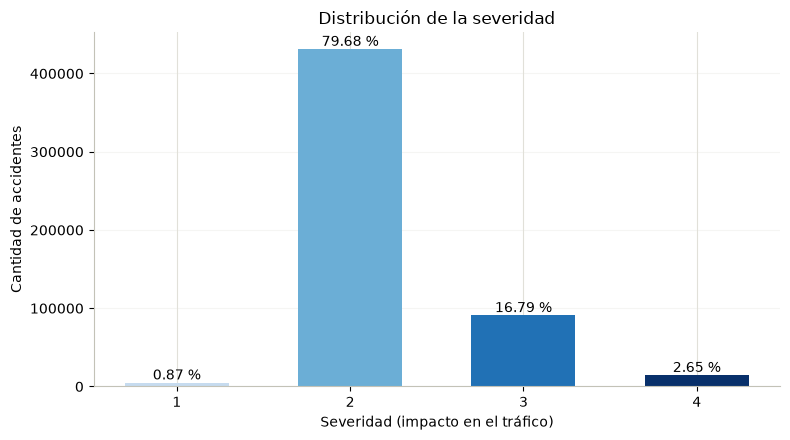

In [11]:
sev = df["Severity"].value_counts().sort_index()
sev_pct = sev / sev.sum() * 100
print(sev_pct.round(2).rename("%").to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
colores_sev = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]   # un solo tono: claro = bajo impacto, oscuro = alto
ax.bar(sev.index.astype(str), sev.values, color=colores_sev, width=0.6)
for i, (v, p) in enumerate(zip(sev.values, sev_pct.values)):
    ax.text(i, v, f"{p:.2f} %", ha="center", va="bottom")
ax.set_xlabel("Severidad (impacto en el tráfico)")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Distribución de la severidad")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_01_distribucion_severidad")
plt.show()

**Interpretación:** el **79,68 %** de los accidentes es de severidad 2. Los de **alto impacto (3–4) suman 19,44 %** (16,79 % + 2,65 %), unos 105 000 casos en la muestra: una minoría, pero suficientemente grande para describir sus patrones con confianza. La severidad 1 es casi inexistente (0,87 %).

### I.6.4 ¿Dónde? Concentración por estado

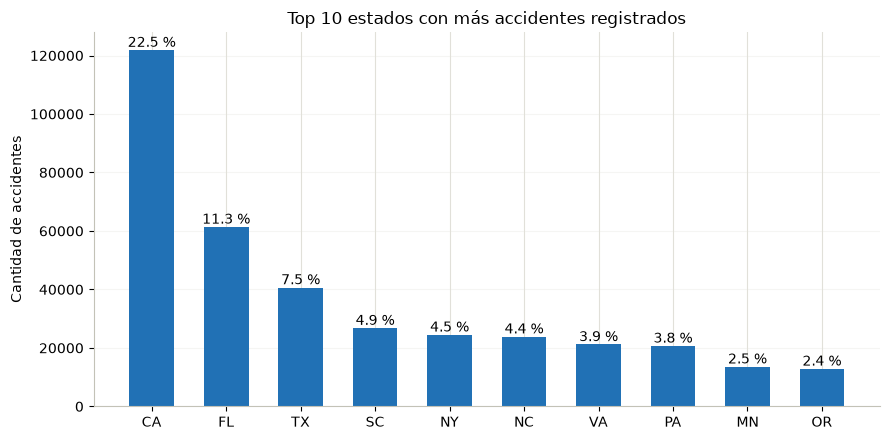

In [12]:
top_estados = df["State"].value_counts().head(10)
pct_est = top_estados / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top_estados.index, top_estados.values, color="#2171b5", width=0.6)
for i, (v, p) in enumerate(zip(top_estados.values, pct_est.values)):
    ax.text(i, v, f"{p:.1f} %", ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Top 10 estados con más accidentes registrados")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_02_top10_estados")
plt.show()

**Interpretación:** California concentra el **22,5 %** de los accidentes, el doble que Florida (11,3 %), seguida de Texas (7,5 %), Carolina del Sur (4,9 %) y Nueva York (4,5 %). Solo 3 estados reúnen el **41 %** de los registros. Esta concentración puede reflejar el tamaño de la población y de la red vial, pero también una **mayor cobertura de reportes** en ciertos estados → al comparar regiones hay que tener en cuenta cuánto reporta cada fuente en cada estado.

### I.6.5 ¿Cuándo? Registros por año

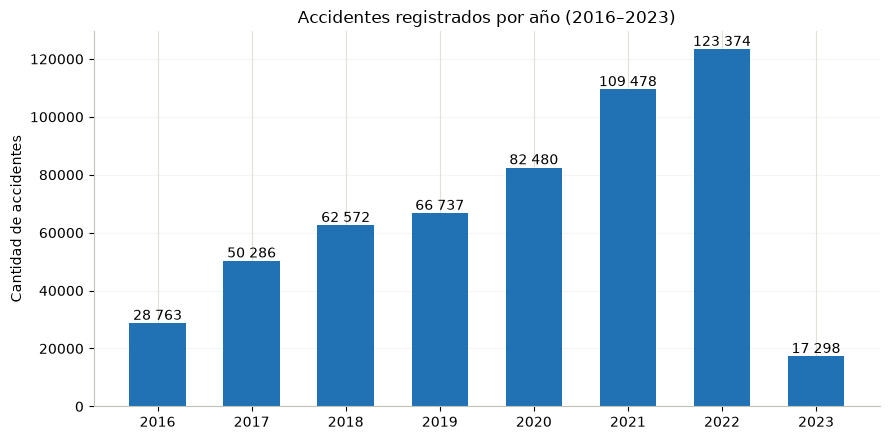

In [13]:
# El año son los 4 primeros caracteres de Start_Time (texto); la fecha se convierte recién en la Parte II
por_anio = df["Start_Time"].str[:4].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_anio.index, por_anio.values, color="#2171b5", width=0.6)
for i, v in enumerate(por_anio.values):
    ax.text(i, v, f"{v:,}".replace(",", " "), ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Accidentes registrados por año (2016–2023)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_03_accidentes_por_anio")
plt.show()

**Interpretación:** los accidentes registrados crecen cada año, de 50 286 en 2017 a **123 374 en 2022** (más del doble). El año **2023 aparece bajo (17 298) porque solo incluye enero a marzo**, y 2016 empieza en febrero, por lo que esos dos años **no son comparables** con los demás. El crecimiento puede deberse en parte a una **mayor cobertura de las fuentes** con el tiempo y no necesariamente a más accidentes reales → no debe leerse como "el tránsito empeoró".

---
## I.7 Diccionario de datos

### I.7.1 Catálogo técnico (automático)
Generado con código para que coincida siempre con los datos reales: tipo, nulos, valores distintos y un ejemplo tomado del propio dataset.

In [14]:
catalogo = pd.DataFrame({
    "tipo_pandas": df[COLUMNAS].dtypes.astype(str),
    "no_nulos": df[COLUMNAS].notna().sum(),
    "% nulos": (df[COLUMNAS].isna().mean() * 100).round(2),
    "valores_distintos": df[COLUMNAS].nunique(),
    "ejemplo_real": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in COLUMNAS],
})
catalogo

,tipo_pandas,no_nulos,% nulos,valores_distintos,ejemplo_real
ID,str,540988,0.00,540988,A-104248
Source,str,540988,0.00,3,Source2
Severity,int64,540988,0.00,4,2
Start_Time,str,540988,0.00,525916,2016-04-25 17:18:11
End_Time,str,540988,0.00,533773,2016-04-25 18:18:11
Start_Lat,float64,540988,0.00,395206,33.939304
Start_Lng,float64,540988,0.00,396219,-117.218231
End_Lat,float64,302822,44.02,235734,34.14825
End_Lng,float64,302822,44.02,236919,-118.08481
Distance(mi),float64,540988,0.00,10915,0.01


### I.7.2 Diccionario para cualquier persona

In [15]:
diccionario = pd.DataFrame([
    ("ID", "Código del accidente", "Identificador único de cada accidente", "Identificador (texto)", "Único por registro", "Verificar duplicados (unicidad)"),
    ("Source", "Fuente", "Proveedor de datos que reportó el accidente", "Categórica nominal", "Source1, Source2, Source3", "Clave: podría medir distinto la severidad (Parte II)"),
    ("Severity", "Severidad", "Impacto del accidente en el tráfico (no en las personas)", "Categórica ordinal", "1 (bajo) a 4 (alto)", "Define el 'colapso del tráfico' (3–4)"),
    ("Start_Time", "Inicio", "Momento en que empezó el accidente (hora local)", "Temporal", "Fecha y hora entre feb-2016 y mar-2023", "Sub-pregunta 1: hora y día"),
    ("End_Time", "Fin", "Momento en que terminó el impacto en el tráfico", "Temporal", "Posterior a Start_Time", "Mide la duración del bloqueo"),
    ("Start_Lat", "Latitud de inicio", "Latitud del punto donde ocurrió el accidente", "Numérica continua", "Grados; 24 a 50 (EE.UU. continental)", "Sub-pregunta 2: dónde"),
    ("Start_Lng", "Longitud de inicio", "Longitud del punto donde ocurrió el accidente", "Numérica continua", "Grados; −125 a −66 (EE.UU. continental)", "Sub-pregunta 2: dónde"),
    ("End_Lat", "Latitud de fin del tramo", "Latitud del punto donde termina el tramo afectado", "Numérica continua", "Grados; 24 a 50", "Extensión del impacto (solo Source1)"),
    ("End_Lng", "Longitud de fin del tramo", "Longitud del punto donde termina el tramo afectado", "Numérica continua", "Grados; −125 a −66", "Extensión del impacto (solo Source1)"),
    ("Distance(mi)", "Tramo afectado", "Longitud de vía afectada", "Numérica continua", "Millas (1 mi ≈ 1,61 km), ≥ 0", "Extensión del impacto"),
    ("City", "Ciudad", "Ciudad del accidente", "Categórica nominal", "Nombres de ciudades", "Comparar zonas"),
    ("State", "Estado", "Estado de EE.UU.", "Categórica nominal", "Código de 2 letras (49 estados)", "Comparar regiones"),
    ("Zipcode", "Código postal", "Código postal del lugar", "Categórica", "5 dígitos (a veces con extensión)", "Ubicación detallada"),
    ("Country", "País", "País del accidente", "Categórica", "Solo 'US'", "Sin aporte (valor constante)"),
    ("Timezone", "Zona horaria", "Zona horaria del lugar", "Categórica nominal", "4 zonas (US/Eastern, US/Pacific, …)", "Interpretar la hora local"),
    ("Weather_Timestamp", "Hora del clima", "Momento en que se midió el clima", "Temporal", "Cercano a Start_Time", "Comprobar que el clima corresponde al accidente"),
    ("Temperature(F)", "Temperatura", "Temperatura del aire", "Numérica continua", "°F; rango realista −40 a 130", "Contexto climático"),
    ("Humidity(%)", "Humedad", "Humedad relativa del aire", "Numérica continua", "%, 0 a 100", "Contexto climático"),
    ("Pressure(in)", "Presión", "Presión atmosférica", "Numérica continua", "inHg (presión de estación); rango realista 17 a 32", "Contexto climático"),
    ("Visibility(mi)", "Visibilidad", "Distancia a la que se ve con claridad", "Numérica continua", "Millas, ≥ 0 (tope habitual 10)", "Sub-pregunta 3: condición de riesgo"),
    ("Wind_Speed(mph)", "Viento", "Velocidad del viento", "Numérica continua", "mph; rango realista 0 a 150", "Condición de riesgo"),
    ("Precipitation(in)", "Lluvia", "Cantidad de precipitación", "Numérica continua", "Pulgadas, ≥ 0", "Sub-pregunta 3: intensidad de la lluvia"),
    ("Weather_Condition", "Clima", "Condición climática descrita en texto", "Categórica nominal", "108 categorías (Fair, Rain, Fog, Snow…)", "Sub-pregunta 3: clima y colapso"),
    ("Traffic_Signal", "Semáforo", "¿Hay semáforo cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Crossing", "Cruce peatonal", "¿Hay cruce peatonal cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Junction", "Rampa de autopista", "¿Hay una rampa, salida o entrada de autopista a ≤ 100 m?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Stop", "Señal de pare", "¿Hay señal de pare cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Roundabout", "Rotonda", "¿Ocurrió en una rotonda?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Sunrise_Sunset", "Día / noche", "Si era de día o de noche", "Categórica binaria", "Day / Night", "Condición de luz"),
], columns=["Columna", "Nombre simple", "Descripción", "Tipo o escala", "Unidad o dominio", "Importancia para la pregunta"])

with pd.option_context("display.max_colwidth", None):
    display(diccionario)

,Columna,Nombre simple,Descripción,Tipo o escala,Unidad o dominio,Importancia para la pregunta
0,ID,Código del accidente,Identificador único de cada accidente,Identificador (texto),Único por registro,Verificar duplicados (unicidad)
1,Source,Fuente,Proveedor de datos que reportó el accidente,Categórica nominal,"Source1, Source2, Source3",Clave: podría medir distinto la severidad (Parte II)
2,Severity,Severidad,Impacto del accidente en el tráfico (no en las personas),Categórica ordinal,1 (bajo) a 4 (alto),Define el 'colapso del tráfico' (3–4)
3,Start_Time,Inicio,Momento en que empezó el accidente (hora local),Temporal,Fecha y hora entre feb-2016 y mar-2023,Sub-pregunta 1: hora y día
4,End_Time,Fin,Momento en que terminó el impacto en el tráfico,Temporal,Posterior a Start_Time,Mide la duración del bloqueo
5,Start_Lat,Latitud de inicio,Latitud del punto donde ocurrió el accidente,Numérica continua,Grados; 24 a 50 (EE.UU. continental),Sub-pregunta 2: dónde
6,Start_Lng,Longitud de inicio,Longitud del punto donde ocurrió el accidente,Numérica continua,Grados; −125 a −66 (EE.UU. continental),Sub-pregunta 2: dónde
7,End_Lat,Latitud de fin del tramo,Latitud del punto donde termina el tramo afectado,Numérica continua,Grados; 24 a 50,Extensión del impacto (solo Source1)
8,End_Lng,Longitud de fin del tramo,Longitud del punto donde termina el tramo afectado,Numérica continua,Grados; −125 a −66,Extensión del impacto (solo Source1)
9,Distance(mi),Tramo afectado,Longitud de vía afectada,Numérica continua,"Millas (1 mi ≈ 1,61 km), ≥ 0",Extensión del impacto


> **Nota:** `Junction` no significa "intersección". Según el paper del dataset (Moosavi et al., 2019, tabla 2) es una **rampa, salida o entrada de autopista**; las intersecciones se reflejan en `Crossing`, `Stop` y `Traffic_Signal`. Las variables nuevas (alto impacto, franja horaria, clima agrupado, etc.) se crean y documentan en la Parte II.

---
## I.8 Qué dejó la exploración y qué se revisa en la Parte II

La exploración no corrige nada: deja **observaciones** que la Parte II convierte en reglas de calidad.

| Observación de la exploración | Dónde se vio | Qué hace la Parte II |
|---|---|---|
| `End_Lat`/`End_Lng` (44 %), `Precipitation(in)` (28,6 %) y `Wind_Speed(mph)` (7,4 %) tienen muchos nulos | I.5.4 `info()` | Aplica la regla de máximo 3 % de nulos para elegir columnas |
| `Distance(mi)` vale 0 en al menos el 25 % de los accidentes | I.6.1 `describe()` | Mide cuántos ceros hay y decide si la columna sirve |
| Hay 3 fuentes y Source1 aporta el 56 % | I.6.2 categóricas | Compara la severidad entre fuentes y entre años |
| Las fechas llegan como texto | I.5.4 `info()` | Convierte las fechas y crea hora, franja, día y año |
| `Weather_Condition` tiene 108 categorías | I.6.2 categóricas | Las agrupa en pocas categorías |
| 2016 y 2023 están incompletos | I.6.5 registros por año | Los marca para no comparar años incompletos |
| Podría haber accidentes repetidos | — | Evalúa la unicidad (mismo inicio y misma ubicación) |

---
# PARTE II — Calidad y preparación (Bronze → Silver)

*¿Qué datos son confiables y qué transformamos?* Aquí se evalúan las reglas de calidad en las **6 dimensiones**, se eligen las columnas, se excluye solo lo que tiene justificación y se crean las variables que necesita el análisis. El resultado se guarda como capa **Silver**.

> Esta parte trabaja con la **misma muestra** cargada en la Parte I (celda I.5.1): no se vuelve a leer el CSV de 3 GB ni a muestrear.

---
## II.1 Punto de partida: qué dejó la exploración

La exploración (sección I.8) no corrigió nada: dejó observaciones. Esta capa las convierte en reglas y decisiones:

| Observación de la Parte I | Qué se hace aquí | Sección |
|---|---|---|
| Columnas con muchos nulos (fin del tramo, precipitación, viento) y `Distance(mi)` con muchos ceros | Regla de máximo 3 % de nulos y revisión de los ceros para elegir columnas | II.3 |
| Las fechas llegan como texto | Se convierten a fecha | II.4 |
| Posibles duplicados, valores fuera de rango, clima desfasado, años incompletos | 18 reglas en las 6 dimensiones de calidad | II.5 |
| Hay 3 fuentes de datos | Se compara la severidad entre fuentes y entre años | II.6 |
| `Weather_Condition` tiene 108 categorías | Se agrupa y se crean las demás variables derivadas | II.7 |

**Regla general de esta capa:** no se elimina ningún registro sin una regla escrita, un conteo y un archivo de respaldo.

---
## II.2 Datos de entrada

Se parte de la muestra de la Parte I (`df`), con sus 29 columnas originales y **sin ninguna transformación**.

In [16]:
# Celda II.2.1: tomar la muestra de la Parte I sin modificarla (Bronze queda intacto)
muestra = df.copy()
archivo_bronze = manifest["files"][0]
filas_bronze = filas_originales
COLUMNAS_BRONZE = COLUMNAS
info_muestra = {"fraccion": FRACCION, "semilla": SEMILLA}
print(f"Muestra: {len(muestra):,} filas × {muestra.shape[1]} columnas (de {filas_bronze:,} filas del CSV original)")

Muestra: 540,988 filas × 29 columnas (de 7,728,394 filas del CSV original)


---
## II.3 Selección de columnas: regla del 3 % de nulos

**Regla:** una columna se usa en el análisis solo si tiene **como máximo 3 % de valores nulos** y si ayuda a responder una sub-pregunta.

**¿Por qué 3 %?** Si a una columna le falta el 3 % de los datos, aunque **todos** esos registros fueran de alto impacto, el porcentaje de alto impacto calculado sin ellos se movería como máximo unos 3 puntos. Con 28 % de faltantes (precipitación) el error posible llegaría a 28 puntos, y ninguna conclusión sería confiable.

Además se quitan columnas que, aunque estén completas, no aportan a la pregunta: así la tabla es más liviana y más fácil de explicar.

Antes de decidir se revisan dos observaciones de la Parte I: ¿los nulos del fin del tramo son al azar? y ¿cuántos ceros tiene `Distance(mi)`?

In [17]:
# Celda II.3.0: evidencia para la selección: fin del tramo por fuente y ceros en Distance(mi)
fin_tramo = muestra["End_Lat"].isna().map({True: "End_Lat nulo", False: "End_Lat con dato"})
display(pd.crosstab(muestra["Source"], fin_tramo, margins=True, margins_name="Total"))

ceros_distancia = (muestra["Distance(mi)"] == 0).sum()
print(f"Distance(mi) igual a 0: {ceros_distancia:,} accidentes ({ceros_distancia / len(muestra):.2%})")

End_Lat,End_Lat con dato,End_Lat nulo,Total
Source,,,
Source1,302822,0,302822
Source2,0,231427,231427
Source3,0,6739,6739
Total,302822,238166,540988


Distance(mi) igual a 0: 231,137 accidentes (42.72%)


**Interpretación:** los nulos de `End_Lat`/`End_Lng` **no son al azar**: Source1 siempre registra el fin del tramo y Source2 y Source3 nunca lo hacen. Y el **42,7 %** de los accidentes tiene `Distance(mi)` = 0: un valor *posible*, pero no *plausible* para un accidente que afecta el tráfico; lo más probable es que la fuente no midió el tramo. Ninguna de esas columnas sirve para comparar.

In [18]:
# Celda II.3.1: decidir qué columnas pasan a Silver
MAX_NULOS = 3.0   # % máximo de nulos permitido en una columna del análisis

motivos_uso = {
    "ID": "Clave única del accidente",
    "Source": "Variable de control: cada fuente mide distinto la severidad",
    "Severity": "Variable objetivo (alto impacto = 3 o 4)",
    "Start_Time": "Sub-pregunta 1: cuándo (hora, día, año)",
    "End_Time": "Regla de consistencia (duración)",
    "Start_Lat": "Sub-pregunta 2: dónde (validez de la ubicación)",
    "Start_Lng": "Sub-pregunta 2: dónde (validez de la ubicación)",
    "City": "Sub-pregunta 2: dónde",
    "State": "Sub-pregunta 2: dónde",
    "Weather_Timestamp": "Regla de exactitud (¿el clima es del momento del accidente?)",
    "Visibility(mi)": "Sub-pregunta 3: clima",
    "Weather_Condition": "Sub-pregunta 3: clima",
    "Sunrise_Sunset": "Sub-pregunta 1: condición de luz (día/noche)",
    "Traffic_Signal": "Sub-pregunta 4: vía",
    "Crossing": "Sub-pregunta 4: vía",
    "Junction": "Sub-pregunta 4: vía",
    "Stop": "Sub-pregunta 4: vía",
}
motivos_exclusion = {
    "End_Lat": "Supera 3 % de nulos: solo Source1 registra el fin del tramo",
    "End_Lng": "Supera 3 % de nulos: solo Source1 registra el fin del tramo",
    "Precipitation(in)": "Supera 3 % de nulos",
    "Wind_Speed(mph)": "Supera 3 % de nulos",
    "Distance(mi)": "Sin nulos, pero 42,7 % de ceros no plausibles (celda II.3.0)",
    "Temperature(F)": "No responde a las sub-preguntas (el clima se describe con Weather_Condition)",
    "Humidity(%)": "No responde a las sub-preguntas",
    "Pressure(in)": "No responde a las sub-preguntas",
    "Zipcode": "Detalle innecesario: City y State bastan",
    "Country": "Valor constante (US): no aporta información",
    "Timezone": "No se necesita: Start_Time ya está en hora local",
    "Roundabout": "Sin muestra: muy pocos accidentes en rotondas",
}

seleccion = pd.DataFrame({"% nulos": muestra.isna().mean().mul(100).round(2)})
seleccion["Decisión"] = np.where(seleccion.index.isin(list(motivos_exclusion)), "Se excluye", "Se usa")
seleccion["Motivo"] = [motivos_exclusion.get(c, motivos_uso.get(c)) for c in seleccion.index]
seleccion = seleccion.sort_values(["Decisión", "% nulos"], ascending=[False, False])

with pd.option_context("display.max_colwidth", None):
    display(seleccion)

COLUMNAS_SILVER = list(motivos_uso)
max_nulos_usadas = seleccion.loc[COLUMNAS_SILVER, "% nulos"].max()
assert max_nulos_usadas <= MAX_NULOS, "Una columna seleccionada supera el 3 % de nulos"
print(f"Columnas que pasan a Silver: {len(COLUMNAS_SILVER)} de {len(COLUMNAS_BRONZE)}")
print(f"Máximo de nulos entre las columnas usadas: {max_nulos_usadas:.2f} % (límite {MAX_NULOS} %)")
print(f"Accidentes en rotonda en la muestra: {muestra['Roundabout'].sum()}")

,% nulos,Decisión,Motivo
Visibility(mi),2.30,Se usa,Sub-pregunta 3: clima
Weather_Condition,2.26,Se usa,Sub-pregunta 3: clima
Weather_Timestamp,1.56,Se usa,Regla de exactitud (¿el clima es del momento del accidente?)
Sunrise_Sunset,0.31,Se usa,Sub-pregunta 1: condición de luz (día/noche)
ID,0.00,Se usa,Clave única del accidente
Source,0.00,Se usa,Variable de control: cada fuente mide distinto la severidad
Severity,0.00,Se usa,Variable objetivo (alto impacto = 3 o 4)
Start_Time,0.00,Se usa,"Sub-pregunta 1: cuándo (hora, día, año)"
End_Time,0.00,Se usa,Regla de consistencia (duración)
Start_Lat,0.00,Se usa,Sub-pregunta 2: dónde (validez de la ubicación)


Columnas que pasan a Silver: 17 de 29
Máximo de nulos entre las columnas usadas: 2.30 % (límite 3.0 %)
Accidentes en rotonda en la muestra: 17


In [19]:
# Celda II.3.2: quedarse solo con las columnas seleccionadas
df = muestra[COLUMNAS_SILVER].copy()
del muestra          # libera memoria: Bronze sigue intacto en disco
df.shape

(540988, 17)

**Interpretación de la selección**

- Pasan **17 de 29 columnas**. La que más nulos tiene es `Visibility(mi)` con **2,30 %**, por debajo del límite de 3 %.
- Salen por **exceso de nulos**: `End_Lat`/`End_Lng` (44,02 %), `Precipitation(in)` (28,58 %) y `Wind_Speed(mph)` (7,39 %).
- Sale `Distance(mi)` aunque no tiene nulos: el 42,7 % de sus valores son 0 (celda II.3.0).
- Salen columnas completas pero que no responden la pregunta (`Temperature(F)`, `Humidity(%)`, `Pressure(in)`, `Zipcode`, `Country`, `Timezone`) y `Roundabout`, que tiene solo 17 casos en más de medio millón de accidentes.

---
## II.4 Tipos de datos

Las fechas llegan como texto (sección I.5). Se convierten a fecha; si alguna no se puede leer queda como nula y se cuenta (no se inventa un valor).

In [20]:
# Celda II.4.1: convertir fechas y revisar que no se pierdan valores en la conversión
for col in ["Start_Time", "End_Time", "Weather_Timestamp"]:
    nulos_antes = df[col].isna().sum()
    df[col] = pd.to_datetime(df[col], format="mixed", errors="coerce")
    print(f"{col:<18} fechas que no se pudieron leer: {df[col].isna().sum() - nulos_antes}")

df.info(memory_usage="deep")

Start_Time         fechas que no se pudieron leer: 0
End_Time           fechas que no se pudieron leer: 0
Weather_Timestamp  fechas que no se pudieron leer: 0
<class 'pandas.DataFrame'>
RangeIndex: 540988 entries, 0 to 540987
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ID                 540988 non-null  str           
 1   Source             540988 non-null  str           
 2   Severity           540988 non-null  int64         
 3   Start_Time         540988 non-null  datetime64[ns]
 4   End_Time           540988 non-null  datetime64[ns]
 5   Start_Lat          540988 non-null  float64       
 6   Start_Lng          540988 non-null  float64       
 7   City               540969 non-null  str           
 8   State              540988 non-null  str           
 9   Weather_Timestamp  532555 non-null  datetime64[us]
 10  Visibility(mi)     528532 non-null  float64       
 11  Weather_

**Interpretación:** las tres fechas se convierten **sin perder ningún valor** (los 8 433 nulos de `Weather_Timestamp` ya venían vacíos desde Bronze). `Severity` es entera, las coordenadas y la visibilidad son decimales y los elementos de la vía son booleanos. La tabla ocupa mucho menos memoria que la muestra completa porque tiene 12 columnas menos.

---
## II.5 Reglas de calidad en las 6 dimensiones

Se usan las seis dimensiones de **DAMA-DMBOK** vistas en clase. Cada regla dice **qué se exige**, **a cuántos registros afecta** y **qué se hace** con los que no cumplen:

| Dimensión | Pregunta que responde |
|---|---|
| **Completitud** | ¿Están los datos que necesitamos? |
| **Unicidad** | ¿Cada accidente aparece una sola vez? |
| **Validez** | ¿Los valores están dentro de su dominio posible? |
| **Consistencia** | ¿Los campos relacionados (y las fuentes) cuentan la misma historia? |
| **Exactitud (plausibilidad)** | ¿El dato describe bien la realidad del accidente? Sin una fuente externa para contrastar, se revisa si es creíble |
| **Oportunidad** | ¿El periodo cubierto es suficiente y vigente para la pregunta? |

**Tres tratamientos posibles:** *Excluir* (solo si el error contamina los conteos), *Marcar* (se crea una columna indicadora y se decide en el análisis) o *Conservar* (el problema no afecta o se maneja excluyendo el registro solo del análisis que usa esa columna).

In [21]:
# Celda II.5.0: función para registrar cada regla
reglas = []


def evaluar(dimension, regla, cumple, tratamiento, base=None):
    # Registra una regla. base = registros a los que aplica (por defecto, todos)
    if base is None:
        base = pd.Series(True, index=df.index)
    cumple = cumple.fillna(False).astype(bool)
    evaluados = int(base.sum())
    incumplen = int((base & ~cumple).sum())
    reglas.append({
        "Dimensión": dimension, "Regla": regla, "Evaluados": evaluados, "Incumplen": incumplen,
        "% Cumple": round((evaluados - incumplen) / evaluados * 100, 2),
        "Tratamiento en Silver": tratamiento,
    })


con_dato = lambda c: df[c].notna()

In [22]:
# Celda II.5.1: Completitud
for col in ["Severity", "Start_Time", "State"]:
    evaluar("Completitud", f"{col} no nulo", df[col].notna(), "Conservar (100 % completo)")
evaluar("Completitud", "City no nulo", df["City"].notna(),
        "Conservar; sin ciudad solo sale del análisis por ciudad")
evaluar("Completitud", "Weather_Condition no nulo", df["Weather_Condition"].notna(),
        "Conservar; sin clima solo sale del análisis de clima")
evaluar("Completitud", "Visibility(mi) no nulo", df["Visibility(mi)"].notna(),
        "Conservar; sin visibilidad solo sale del análisis de visibilidad")
evaluar("Completitud", "Sunrise_Sunset no nulo", df["Sunrise_Sunset"].notna(),
        "Conservar; sin dato solo sale del análisis día/noche")

In [23]:
# Celda II.5.2: Unicidad
evaluar("Unicidad", "ID único", ~df["ID"].duplicated(keep=False), "Conservar (no hay repetidos)")
duplicado_probable = df.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"])   # deja el primero
evaluar("Unicidad", "Sin duplicado probable (mismo inicio y misma ubicación)", ~duplicado_probable,
        "EXCLUIR la copia (se conserva el primer registro)")

# Ejemplo: dos ID distintos con la misma hora y las mismas coordenadas
ejemplo = df[df.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"], keep=False)]
ejemplo.sort_values(["Start_Time", "ID"])[["ID", "Source", "Severity", "Start_Time", "Start_Lat", "Start_Lng", "City"]].head(4)

,ID,Source,Severity,Start_Time,Start_Lat,Start_Lng,City
28299,A-35167,Source2,2,2016-04-19 18:03:57,38.411682,-122.794876,Santa Rosa
11957,A-35198,Source2,2,2016-04-19 18:03:57,38.411682,-122.794876,Santa Rosa
232818,A-3422977,Source1,2,2016-05-26 14:13:10,33.829270,-117.460370,Corona
242899,A-3422980,Source1,2,2016-05-26 14:13:10,33.829270,-117.460370,Corona


In [24]:
# Celda II.5.3: Validez
evaluar("Validez", "Severity entre 1 y 4", df["Severity"].between(1, 4), "Excluir si incumple")
evaluar("Validez", "Start_Time entre 2016 y marzo 2023",
        df["Start_Time"].between(pd.Timestamp("2016-01-01"), pd.Timestamp("2023-04-01")), "Excluir si incumple")
evaluar("Validez", "Coordenadas dentro de EE.UU. continental",
        df["Start_Lat"].between(24, 50) & df["Start_Lng"].between(-125, -66), "Excluir si incumple")
evaluar("Validez", "Visibility(mi) mayor o igual a 0", df["Visibility(mi)"] >= 0,
        "Convertir a nulo si incumple", base=con_dato("Visibility(mi)"))
evaluar("Validez", "Sunrise_Sunset es Day o Night", df["Sunrise_Sunset"].isin(["Day", "Night"]),
        "Convertir a nulo si incumple", base=con_dato("Sunrise_Sunset"))

In [25]:
# Celda II.5.4: Consistencia entre columnas
duracion_min = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
evaluar("Consistencia", "End_Time posterior a Start_Time", duracion_min > 0, "Excluir si incumple")
evaluar("Consistencia", "Duración de máximo 24 h", duracion_min <= 24 * 60,
        "MARCAR (flag_duracion_irreal); la duración no se usa en el análisis")

In [26]:
# Celda II.5.5: Exactitud (plausibilidad)
desfase_clima_s = (df["Weather_Timestamp"] - df["Start_Time"]).abs().dt.total_seconds()
evaluar("Exactitud (plausibilidad)", "Clima medido a máximo 1 h del accidente", desfase_clima_s <= 3600,
        "MARCAR (clima_confiable); el análisis de clima usa solo los confiables",
        base=con_dato("Weather_Timestamp"))

In [27]:
# Celda II.5.6: Oportunidad
anio = df["Start_Time"].dt.year.rename("anio")
evaluar("Oportunidad", "Accidente en un año completo (2017–2022)", anio.between(2017, 2022),
        "MARCAR (anio_completo); no se comparan años incompletos")

In [28]:
# Celda II.5.7: resultado consolidado de las reglas
calidad = pd.DataFrame(reglas)
with pd.option_context("display.max_colwidth", 80):
    display(calidad)

,Dimensión,Regla,Evaluados,Incumplen,% Cumple,Tratamiento en Silver
0,Completitud,Severity no nulo,540988,0,100.00,Conservar (100 % completo)
1,Completitud,Start_Time no nulo,540988,0,100.00,Conservar (100 % completo)
2,Completitud,State no nulo,540988,0,100.00,Conservar (100 % completo)
3,Completitud,City no nulo,540988,19,100.00,Conservar; sin ciudad solo sale del análisis por ciudad
4,Completitud,Weather_Condition no nulo,540988,12232,97.74,Conservar; sin clima solo sale del análisis de clima
5,Completitud,Visibility(mi) no nulo,540988,12456,97.70,Conservar; sin visibilidad solo sale del análisis de visibilidad
6,Completitud,Sunrise_Sunset no nulo,540988,1689,99.69,Conservar; sin dato solo sale del análisis día/noche
7,Unicidad,ID único,540988,0,100.00,Conservar (no hay repetidos)
8,Unicidad,Sin duplicado probable (mismo inicio y misma ubicación),540988,3698,99.32,EXCLUIR la copia (se conserva el primer registro)
9,Validez,Severity entre 1 y 4,540988,0,100.00,Excluir si incumple


**Interpretación de las reglas**

- **Completitud:** las variables centrales (`Severity`, `Start_Time`, `State`) están al 100 %. Las del clima tienen entre 97,7 % y 97,8 % de cumplimiento: los registros sin dato se mantienen en Silver y solo se apartan del análisis que necesita esa columna (como en el notebook de clase de Elecciones 2021, no se convierte una ausencia en un valor).
- **Unicidad:** el `ID` no se repite, pero **3 698 registros (0,68 %)** tienen exactamente el mismo inicio y las mismas coordenadas que otro. Es la **única regla que obliga a excluir**: un accidente contado dos veces infla los conteos por hora y lugar. El paper del dataset (Moosavi et al., 2019) ya eliminaba duplicados entre fuentes con un criterio parecido (menos de 250 m y 10 minutos).
- **Validez:** todas las reglas se cumplen al 100 %; no hay nada que corregir.
- **Consistencia:** ningún accidente termina antes de empezar, pero **2 474 (0,46 %)** duran más de 24 h. Se marcan y no se excluyen, porque la duración no se usa en el análisis.
- **Exactitud:** en **6 566 registros (1,23 % de los que tienen dato)** el clima se midió a más de 1 h del accidente. Según el paper, el clima se toma de la **estación de aeropuerto más cercana**; si además está desfasado, no describe bien el momento del accidente. Se marcan como no confiables para el análisis de clima.
- **Oportunidad:** 2016 (desde febrero) y 2023 (solo enero a marzo) son años incompletos; se marcan para no compararlos con años completos.

---
## II.6 Consistencia de la severidad: entre fuentes y en el tiempo

La severidad es la variable objetivo, pero las reglas de la sección II.5 solo dicen que es válida (1 a 4) y completa. Falta lo más importante: ¿se mide **igual en todas las fuentes** y **igual en todos los años**? Si no, comparar zonas u horas mezclando registros daría resultados falsos.

In [29]:
# Celda II.6.1: niveles de severidad y % de alto impacto (3–4) en cada fuente
alto_impacto = df["Severity"] >= 3
sev_fuente = pd.crosstab(df["Source"], df["Severity"], normalize="index").mul(100).round(2)
sev_fuente["% alto impacto (3–4)"] = (alto_impacto.groupby(df["Source"]).mean() * 100).round(2)
sev_fuente

Severity,1,2,3,4,% alto impacto (3–4)
Source,,,,,
Source1,0.66,91.21,3.72,4.41,8.13
Source2,1.05,65.05,33.47,0.43,33.90
Source3,4.21,64.24,31.44,0.10,31.55


**Interpretación:** la severidad **no se mide igual entre fuentes**. Source1 clasifica como alto impacto solo al **8,13 %** de sus accidentes, mientras que Source2 y Source3 lo hacen con el **33,90 %** y el **31,55 %**: cuatro veces más. Además Source1 concentra el nivel 4 y Source2 el nivel 3. Una zona con más registros de Source2 parecería tener más "colapsos" solo por cómo se registran.

In [30]:
# Celda II.6.2: % de alto impacto por año y fuente
conteo_fuente_anio = pd.crosstab(anio, df["Source"])
tasa_fuente_anio = pd.crosstab(anio, df["Source"], values=alto_impacto, aggfunc="mean").mul(100).round(1)

print("Accidentes por año y fuente")
display(conteo_fuente_anio)
print("% de alto impacto por año y fuente")
display(tasa_fuente_anio)

Accidentes por año y fuente


Source,Source1,Source2,Source3
anio,,,
2016,9119,19519,125
2017,11962,37790,534
2018,11684,50079,809
2019,18348,47064,1325
2020,49581,31397,1502
2021,77986,30201,1291
2022,106844,15377,1153
2023,17298,0,0


% de alto impacto por año y fuente


Source,Source1,Source2,Source3
anio,,,
2016,28.8,36.9,39.2
2017,32.7,36.6,49.8
2018,33.2,35.9,48.5
2019,20.8,30.4,36.8
2020,10.2,30.5,29.4
2021,2.5,34.2,17.7
2022,2.7,34.1,22.6
2023,2.9,NaN,NaN


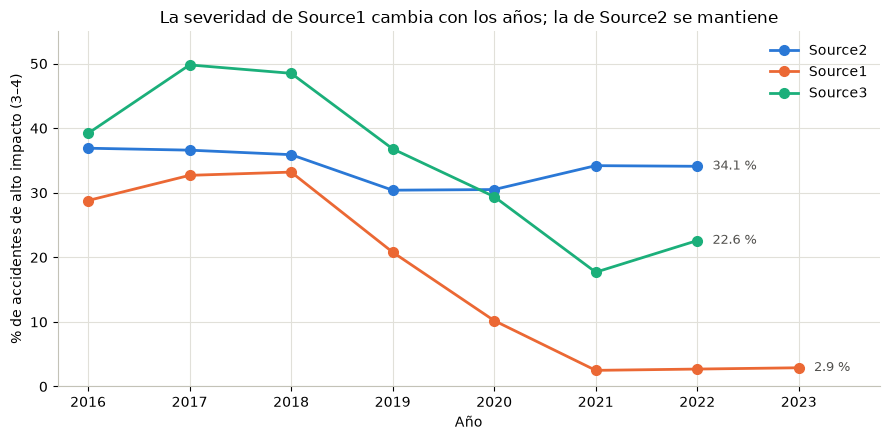

In [31]:
# Celda II.6.3: gráfico de la tendencia por fuente
COLORES_FUENTE = {"Source2": "#2a78d6", "Source1": "#eb6834", "Source3": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 4.5))
for fuente, color in COLORES_FUENTE.items():
    serie = tasa_fuente_anio[fuente].dropna()
    ax.plot(serie.index, serie.values, marker="o", markersize=7, linewidth=2, color=color, label=fuente)
    ax.text(serie.index[-1] + 0.15, serie.values[-1], f"{serie.values[-1]:.1f} %", va="center", fontsize=9, color="#52514e")
ax.set_xlim(2015.7, 2023.8)
ax.set_ylim(0, 55)
ax.set_xlabel("Año")
ax.set_ylabel("% de accidentes de alto impacto (3–4)")
ax.set_title("La severidad de Source1 cambia con los años; la de Source2 se mantiene")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
guardar_figura(fig, "silver_01_alto_impacto_por_fuente_y_anio")
plt.show()

In [32]:
# Celda II.6.4: ¿qué niveles de severidad usa Source1 cada año?
pd.crosstab(anio[df["Source"] == "Source1"], df.loc[df["Source"] == "Source1", "Severity"])

Severity,1,2,3,4
anio,,,,
2016,0,6496,1582,1041
2017,0,8050,2205,1707
2018,0,7804,2125,1755
2019,0,14526,2121,1701
2020,2013,42501,3222,1845
2021,0,76053,0,1933
2022,0,103967,0,2877
2023,0,16795,0,503


**Interpretación: la severidad tampoco es estable en el tiempo**

- **Source2** mantiene entre **30 % y 37 %** de accidentes de alto impacto todos los años (2016–2022): su criterio parece estable. (En 2022 empieza a usar el nivel 1 en vez del 2, pero la proporción de niveles 3–4 sigue en 34 %).
- **Source1** baja de **~33 %** (2016–2018) a **10 %** (2020) y a **menos de 3 %** desde 2021. Además, desde 2021 **ya no usa el nivel 3**: solo registra niveles 2 y 4.
- **Source3** es pequeña (1,25 % de la muestra) y también varía.

**¿Es creíble que los colapsos del tráfico se hayan reducido 10 veces en 4 años?** No parece plausible; es más probable que **Source1 haya cambiado su forma de asignar la severidad**. Esto es una **hipótesis**: solo el mantenedor del dataset puede confirmarla.

**Decisión: grupos comparables.** La severidad solo se comparará dentro de grupos que usan un criterio estable (registros contados después de excluir duplicados, sección II.7):

| Grupo | Registros | Por qué es comparable |
|---|---|---|
| **A: Source2 2016–2022** | 231 374 | Proporción de alto impacto estable (30–37 %) en todos sus años (feb-2016 a sep-2022) |
| **B: Source1 2021–2023** | 199 249 | Proporción estable (2,5–2,9 %) y mismo uso de niveles (2 y 4) |
| **Sin comparar** | 106 667 | Source1 2016–2020 (criterio en transición) y Source3 (muy pocos registros) |

Los registros "sin comparar" **no se borran**: siguen sirviendo para contar accidentes por hora o lugar; solo no se usan para comparar severidad. Un patrón se considerará confiable si aparece **en los dos grupos**, que son fuentes y periodos distintos.

---
## II.7 Tratamiento: excluir, marcar y crear variables

In [33]:
# Celda II.7.1: excluir los duplicados probables (se guardan aparte para auditoría)
rechazados = df[duplicado_probable].copy()
rechazados["motivo_rechazo"] = "Duplicado probable: mismo Start_Time, Start_Lat y Start_Lng que otro registro"
silver = df[~duplicado_probable].copy()

print(f"Registros de la muestra : {len(df):,}")
print(f"Excluidos (duplicados)  : {len(rechazados):,} ({len(rechazados) / len(df):.2%})")
print(f"Registros en Silver     : {len(silver):,}")
print("\nExcluidos por fuente:")
print(rechazados["Source"].value_counts().to_string())

Registros de la muestra : 540,988
Excluidos (duplicados)  : 3,698 (0.68%)
Registros en Silver     : 537,290

Excluidos por fuente:
Source
Source1    3641
Source2      53
Source3       4


**Interpretación:** casi todos los duplicados (3 641 de 3 698) vienen de **Source1**: son el mismo accidente con dos `ID` distintos, misma hora y mismas coordenadas (ver el ejemplo de la celda II.5.2). Excluirlos cambia muy poco el total (0,68 %) pero evita contar dos veces el mismo hecho.

In [34]:
# Celda II.7.2: marcas de calidad (no eliminan registros)
silver["duracion_min"] = (silver["End_Time"] - silver["Start_Time"]).dt.total_seconds() / 60
silver["flag_duracion_irreal"] = silver["duracion_min"] > 24 * 60

desfase = (silver["Weather_Timestamp"] - silver["Start_Time"]).abs().dt.total_seconds()
silver["clima_confiable"] = desfase <= 3600      # sin hora del clima → False

silver["anio"] = silver["Start_Time"].dt.year
silver["anio_completo"] = silver["anio"].between(2017, 2022)

silver[["flag_duracion_irreal", "clima_confiable", "anio_completo"]].mean().mul(100).round(2).to_frame("% True")

,% True
flag_duracion_irreal,0.45
clima_confiable,97.23
anio_completo,91.46


In [35]:
# Celda II.7.3: variables de tiempo
DIAS = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}


def franja_horaria(hora):
    # Franjas usadas por los autores del dataset (Moosavi et al., 2019, nota 7)
    if 6 <= hora < 10:
        return "06-10 Punta mañana"
    if 10 <= hora < 15:
        return "10-15 Mediodía"
    if 15 <= hora < 19:
        return "15-19 Punta tarde"
    if 19 <= hora < 22:
        return "19-22 Noche"
    return "22-06 Madrugada"


silver["mes"] = silver["Start_Time"].dt.month
silver["hora"] = silver["Start_Time"].dt.hour
silver["franja_horaria"] = silver["hora"].map(franja_horaria)
silver["dia_semana"] = silver["Start_Time"].dt.day_of_week.map(DIAS)
silver["tipo_dia"] = np.where(silver["Start_Time"].dt.day_of_week >= 5, "Fin de semana", "Laborable")

silver[["Start_Time", "anio", "mes", "hora", "franja_horaria", "dia_semana", "tipo_dia"]].head()

,Start_Time,anio,mes,hora,franja_horaria,dia_semana,tipo_dia
0,2016-04-25 17:18:11,2016,4,17,15-19 Punta tarde,Lunes,Laborable
1,2017-01-10 09:40:16,2017,1,9,06-10 Punta mañana,Martes,Laborable
2,2016-09-02 17:27:56,2016,9,17,15-19 Punta tarde,Viernes,Laborable
3,2016-09-29 18:07:37,2016,9,18,15-19 Punta tarde,Jueves,Laborable
4,2017-05-03 12:12:18,2017,5,12,10-15 Mediodía,Miércoles,Laborable


In [36]:
# Celda II.7.4: agrupar las descripciones del clima en pocas categorías
def agrupar_clima(texto):
    # El orden importa: "Light Rain with Thunder" es tormenta, no lluvia
    t = texto.lower()
    if "thunder" in t or "t-storm" in t:
        return "Tormenta"
    if any(p in t for p in ["snow", "sleet", "wintry", "freezing", "ice", "hail"]):
        return "Nieve o hielo"
    if any(p in t for p in ["rain", "drizzle", "shower"]):
        return "Lluvia"
    if any(p in t for p in ["fog", "mist", "haze", "smoke", "dust", "sand"]):
        return "Niebla o humo"
    if "cloud" in t or "overcast" in t:
        return "Nublado"
    if "fair" in t or "clear" in t:
        return "Despejado"
    return "Otro"


mapa_clima = {texto: agrupar_clima(texto) for texto in silver["Weather_Condition"].dropna().unique()}
silver["clima_grupo"] = silver["Weather_Condition"].map(mapa_clima)

resumen_clima = (pd.Series(mapa_clima, name="grupo").rename_axis("descripcion").reset_index()
                 .groupby("grupo")["descripcion"]
                 .agg(descripciones_originales="size", ejemplos=lambda s: ", ".join(s.head(4))))
resumen_clima["accidentes"] = silver["clima_grupo"].value_counts()
with pd.option_context("display.max_colwidth", None):
    display(resumen_clima.sort_values("accidentes", ascending=False))

,descripciones_originales,ejemplos,accidentes
grupo,,,
Despejado,3,"Clear, Fair, Fair / Windy",236357
Nublado,8,"Partly Cloudy, Scattered Clouds, Overcast, Mostly Cloudy",220273
Lluvia,19,"Light Rain, Rain, Light Drizzle, Heavy Rain",35606
Niebla o humo,20,"Fog, Haze, Mist, Smoke",14123
Nieve o hielo,35,"Light Snow, Light Freezing Rain, Light Ice Pellets, Snow",12349
Tormenta,18,"Heavy Thunderstorms and Rain, Light Thunderstorms and Rain, Thunderstorms and Rain, Thunderstorm",6182
Otro,5,"Volcanic Ash, N/A Precipitation, Squalls / Windy, Squalls",250


In [37]:
# Celda II.7.5: visibilidad en rangos, alto impacto y grupo comparable
silver["visibilidad_grupo"] = pd.cut(silver["Visibility(mi)"], bins=[0, 1, 5, np.inf], right=False,
                                     labels=["Muy reducida (<1 mi)", "Reducida (1-5 mi)", "Normal (>=5 mi)"])
silver["alto_impacto"] = silver["Severity"] >= 3

silver["grupo_severidad"] = "Sin comparar"
silver.loc[silver["Source"] == "Source2", "grupo_severidad"] = "A: Source2 2016-2022"
silver.loc[(silver["Source"] == "Source1") & (silver["anio"] >= 2021), "grupo_severidad"] = "B: Source1 2021-2023"

grupos = (silver.groupby("grupo_severidad")
          .agg(accidentes=("ID", "size"), alto_impacto=("alto_impacto", "sum"),
               desde=("Start_Time", "min"), hasta=("Start_Time", "max")))
grupos["% alto impacto"] = (grupos["alto_impacto"] / grupos["accidentes"] * 100).round(2)
grupos["% de Silver"] = (grupos["accidentes"] / len(silver) * 100).round(2)
display(grupos)
print(silver["visibilidad_grupo"].value_counts(dropna=False).to_string())

,accidentes,alto_impacto,desde,hasta,% alto impacto,% de Silver
grupo_severidad,,,,,,
A: Source2 2016-2022,231374,78438,2016-02-08 07:59:35,2022-09-08 14:40:33,33.90,43.06
B: Source1 2021-2023,199249,5158,2021-01-01 00:05:00,2023-03-31 22:59:30,2.59,37.08
Sin comparar,106667,21363,2016-02-08 21:10:10,2022-09-08 10:58:38,20.03,19.85


visibilidad_grupo
Normal (>=5 mi)         481550
Reducida (1-5 mi)        35189
NaN                      12367
Muy reducida (<1 mi)      8184


**Interpretación de las variables creadas**

- `franja_horaria` usa las **cinco franjas que los autores del dataset definieron** para su modelo (06–10, 10–15, 15–19, 19–22 y 22–06), así el análisis se apoya en un criterio externo y no en uno inventado.
- `clima_grupo` resume las más de 100 descripciones de `Weather_Condition` en 7 grupos. "Despejado" y "Nublado" reúnen la gran mayoría; "Otro" (tornado, ceniza volcánica, ráfagas) tiene muy pocos casos y no se interpretará.
- `visibilidad_grupo` separa la visibilidad reducida: como el sensor suele reportar un máximo de 10 millas (sección I.6.1), la mayoría queda en "Normal".
- `grupo_severidad` aplica la decisión de la sección II.6: **A** tiene 33,9 % de alto impacto y **B** 2,6 %. Los dos porcentajes **no se comparan entre sí**; cada patrón se compara contra el promedio de su propio grupo.

---
## II.8 Diccionario de las variables derivadas

Las 17 columnas que vienen de Bronze ya están descritas en el diccionario de la Parte I (sección I.7.2). Aquí se documentan **solo las columnas creadas en esta capa**.

In [38]:
# Celda II.8.1: diccionario de las variables derivadas de Silver
diccionario_silver = pd.DataFrame([
    ("grupo_severidad", "Derivada", "Grupo en el que la severidad es comparable", "Categórica nominal", "A: Source2 2016-2022 · B: Source1 2021-2023 · Sin comparar", "Toda comparación de severidad se hace dentro del grupo"),
    ("alto_impacto", "Derivada", "True si Severity es 3 o 4", "Booleana", "True / False", "Define el 'colapso del tráfico'"),
    ("duracion_min", "Derivada", "Minutos entre inicio y fin", "Numérica continua", "Minutos, > 0", "Solo control de calidad (depende de la fuente)"),
    ("flag_duracion_irreal", "Derivada", "True si la duración supera 24 h", "Booleana", "True / False", "Marca de consistencia"),
    ("anio / mes / hora", "Derivada", "Partes de Start_Time", "Numérica discreta", "2016–2023 · 1–12 · 0–23", "Cuándo"),
    ("anio_completo", "Derivada", "True si el año tiene 12 meses de datos (2017–2022)", "Booleana", "True / False", "Marca de oportunidad"),
    ("franja_horaria", "Derivada", "Franja del día definida por los autores del dataset", "Categórica ordinal", "06-10, 10-15, 15-19, 19-22, 22-06", "Cuándo"),
    ("dia_semana / tipo_dia", "Derivada", "Día de la semana y si es laborable o fin de semana", "Categórica", "Lunes…Domingo · Laborable / Fin de semana", "Cuándo"),
    ("clima_confiable", "Derivada", "True si el clima se midió a máximo 1 h del accidente", "Booleana", "True / False", "Filtro del análisis de clima"),
    ("clima_grupo", "Derivada", "Clima agrupado", "Categórica nominal", "Despejado, Nublado, Lluvia, Tormenta, Nieve o hielo, Niebla o humo, Otro", "Clima"),
    ("visibilidad_grupo", "Derivada", "Visibilidad en tres rangos", "Categórica ordinal", "<1 mi · 1–5 mi · ≥5 mi", "Clima"),
], columns=["Columna", "Origen", "Descripción", "Tipo o escala", "Unidad o dominio", "Uso en el análisis"])

with pd.option_context("display.max_colwidth", None):
    display(diccionario_silver)

,Columna,Origen,Descripción,Tipo o escala,Unidad o dominio,Uso en el análisis
0,grupo_severidad,Derivada,Grupo en el que la severidad es comparable,Categórica nominal,A: Source2 2016-2022 · B: Source1 2021-2023 · Sin comparar,Toda comparación de severidad se hace dentro del grupo
1,alto_impacto,Derivada,True si Severity es 3 o 4,Booleana,True / False,Define el 'colapso del tráfico'
2,duracion_min,Derivada,Minutos entre inicio y fin,Numérica continua,"Minutos, > 0",Solo control de calidad (depende de la fuente)
3,flag_duracion_irreal,Derivada,True si la duración supera 24 h,Booleana,True / False,Marca de consistencia
4,anio / mes / hora,Derivada,Partes de Start_Time,Numérica discreta,2016–2023 · 1–12 · 0–23,Cuándo
5,anio_completo,Derivada,True si el año tiene 12 meses de datos (2017–2022),Booleana,True / False,Marca de oportunidad
6,franja_horaria,Derivada,Franja del día definida por los autores del dataset,Categórica ordinal,"06-10, 10-15, 15-19, 19-22, 22-06",Cuándo
7,dia_semana / tipo_dia,Derivada,Día de la semana y si es laborable o fin de semana,Categórica,Lunes…Domingo · Laborable / Fin de semana,Cuándo
8,clima_confiable,Derivada,True si el clima se midió a máximo 1 h del accidente,Booleana,True / False,Filtro del análisis de clima
9,clima_grupo,Derivada,Clima agrupado,Categórica nominal,"Despejado, Nublado, Lluvia, Tormenta, Nieve o hielo, Niebla o humo, Otro",Clima


---
## II.9 Guardar Silver y registrar la trazabilidad

Se guardan cuatro archivos en `data/silver/us_accidents/`:

| Archivo | Contenido |
|---|---|
| `us_accidents_silver.csv` | La tabla limpia que usa el análisis |
| `rechazados_duplicados.csv` | Los registros excluidos y el motivo (auditoría) |
| `reglas_calidad_silver.csv` y `diccionario_silver.csv` | Metadatos de la capa |
| `registro_silver.json` | Linaje: de qué archivo se partió, cuántas filas entraron y salieron, y cuándo se generó |

In [39]:
# Celda II.9.1: ordenar columnas y guardar la capa Silver
ORDEN_SILVER = ["ID", "Source", "grupo_severidad", "Severity", "alto_impacto",
                "Start_Time", "End_Time", "duracion_min", "flag_duracion_irreal",
                "anio", "anio_completo", "mes", "hora", "franja_horaria", "dia_semana", "tipo_dia", "Sunrise_Sunset",
                "Start_Lat", "Start_Lng", "City", "State",
                "Weather_Timestamp", "clima_confiable", "Weather_Condition", "clima_grupo",
                "Visibility(mi)", "visibilidad_grupo",
                "Junction", "Traffic_Signal", "Crossing", "Stop"]
silver = silver[ORDEN_SILVER]

FORMATO_FECHA = "%Y-%m-%d %H:%M:%S"
silver.to_csv(SILVER_DIR / "us_accidents_silver.csv", index=False, date_format=FORMATO_FECHA)
rechazados.to_csv(SILVER_DIR / "rechazados_duplicados.csv", index=False, date_format=FORMATO_FECHA)
calidad.to_csv(SILVER_DIR / "reglas_calidad_silver.csv", index=False, encoding="utf-8-sig")
diccionario_silver.to_csv(SILVER_DIR / "diccionario_silver.csv", index=False, encoding="utf-8-sig")

registro = {
    "capa": "silver",
    "origen": "data/bronze/us_accidents/" + archivo_bronze["name"],
    "sha256_origen": archivo_bronze["sha256"],
    "filas_bronze": filas_bronze,
    "muestra": {"fraccion": info_muestra["fraccion"], "semilla": info_muestra["semilla"], "filas": len(df)},
    "excluidas_duplicado_probable": len(rechazados),
    "filas_silver": len(silver),
    "columnas_silver": ORDEN_SILVER,
    "generado_utc": datetime.now(timezone.utc).isoformat(),
}
(SILVER_DIR / "registro_silver.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")

for archivo in sorted(SILVER_DIR.iterdir()):
    print(f"  {archivo.relative_to(PROJECT_ROOT)}  ({archivo.stat().st_size / 1024**2:.1f} MB)")

  data\silver\us_accidents\diccionario_silver.csv  (0.0 MB)
  data\silver\us_accidents\rechazados_duplicados.csv  (0.8 MB)
  data\silver\us_accidents\registro_silver.json  (0.0 MB)
  data\silver\us_accidents\reglas_calidad_silver.csv  (0.0 MB)
  data\silver\us_accidents\us_accidents_silver.csv  (145.2 MB)


---
## II.10 Resumen de la capa Silver

**Linaje:** CSV original en Bronze (7 728 394 filas) → muestra fija del 7 % de la Parte I (540 988) → 17 columnas con ≤ 3 % de nulos → fechas convertidas → 18 reglas en 6 dimensiones → 3 698 duplicados probables excluidos → marcas de calidad y variables nuevas → **Silver: 537 290 accidentes y 31 columnas**.

| Qué se hizo | Por qué |
|---|---|
| Se redujeron las columnas de 29 a 17 | Regla del 3 % de nulos y relevancia para la pregunta |
| Se excluyeron 3 698 duplicados probables (0,68 %) | Inflaban los conteos; se guardaron aparte |
| Se marcaron duraciones irreales, clima desfasado y años incompletos | Se deciden en el análisis, sin perder registros |
| Se crearon franja horaria, clima agrupado y visibilidad en rangos | Variables fáciles de explicar y comparar |
| Se crearon dos **grupos comparables** de severidad | La severidad cambia entre fuentes **y** dentro de Source1 con los años |

**Siguiente paso:** la Parte III usa esta tabla Silver (ya en memoria) para el análisis y la capa Gold.

---
# PARTE III — Análisis y conclusiones (Silver → Gold)

*¿Qué patrones aparecen y qué podemos afirmar?* Esta parte solo presenta **resultados y conclusiones**: la calidad y la limpieza ya se hicieron en la Parte II.

---
## III.0 Pregunta, enfoque y reglas para no sobreinterpretar

> ### ¿Cuándo, dónde y bajo qué condiciones un accidente deja de ser un incidente aislado y se convierte en un colapso del tráfico?

**Colapso del tráfico** = accidente de **alto impacto** (severidad 3 o 4). La severidad mide el impacto en el tráfico (por ejemplo, el retraso que genera), **no** la gravedad de las lesiones.

| # | Sub-pregunta | Variables (todas con ≤ 3 % de nulos) |
|---|---|---|
| 1 | ¿En qué horas y días se concentran los accidentes de alto impacto? | `hora`, `franja_horaria`, `tipo_dia`, `dia_semana`, `Sunrise_Sunset` |
| 2 | ¿En qué estados y ciudades se concentran? | `State`, `City` |
| 3 | ¿Bajo qué condiciones climáticas aumenta la proporción de alto impacto? | `clima_grupo`, `visibilidad_grupo` (la precipitación se excluyó: 28,58 % de nulos) |
| 4 | ¿Qué elementos de la vía acompañan a los accidentes de alto impacto? | `Junction`, `Traffic_Signal`, `Crossing`, `Stop` |

### Los 4 niveles de análisis en Big Data

| Nivel | Pregunta que responde | Qué se hace en este notebook | Sección |
|---|---|---|---|
| **1. Descriptivo** | ¿Qué pasó? | Frecuencias por hora, día, lugar, clima y vía (análisis univariado) | III.2 |
| **2. Diagnóstico** | ¿Con qué se asocia? ¿Por qué podría pasar? | Comparaciones dentro de grupos comparables (bivariado y multivariado) | III.3 |
| **3. Predictivo** | ¿Qué podría pasar? | **No se incluye**: queda fuera del alcance de este trabajo | — |
| **4. Prescriptivo** | ¿Qué conviene hacer? | Recomendaciones con su nivel de solidez y lo que falta validar | III.4 |

### Reglas para no dar por cierto un resultado

1. **Solo se compara dentro de un grupo comparable** (sección II.6): **A = Source2 2016–2022** y **B = Source1 2021–2023**. Nunca se mezclan fuentes al hablar de severidad.
2. **Un patrón es "sólido" solo si aparece en los dos grupos** y en la misma dirección. Como A y B son fuentes y periodos distintos, que coincidan hace menos probable que el patrón sea un efecto de cómo registra una sola fuente.
3. **No se interpreta un subgrupo con menos de 500 accidentes**: con pocos casos, unos cuantos accidentes cambian mucho el porcentaje.
4. **Se habla de asociación, no de causa**: los datos muestran *qué ocurre junto*, no *qué lo provoca*.

### Cómo se compara: el índice de alto impacto

Como A tiene ~34 % de alto impacto y B ~3 % (criterios distintos), no se comparan sus porcentajes directamente. Se usa un **índice**:

$$\text{índice} = \frac{\% \text{ de alto impacto del subgrupo}}{\% \text{ de alto impacto promedio de su grupo}}$$

- **1,00** = igual al promedio de su grupo · **1,30** = 30 % más que el promedio · **0,70** = 30 % menos.
- Se considera una diferencia relevante si el índice es **≥ 1,10 o ≤ 0,90** (10 % o más de diferencia).

### Cómo influyen las 6 dimensiones de calidad en los resultados

Las reglas se evaluaron en la Parte II (secciones II.5 y II.6); aquí no se repiten, pero condicionan cómo se lee cada resultado:

| Dimensión | Resultado en la Parte II | Efecto en este análisis |
|---|---|---|
| Completitud | Todas las columnas usadas tienen ≤ 3 % de nulos (máximo 2,30 %) | Un registro sin dato solo sale del análisis que usa esa columna |
| Unicidad | 3 698 duplicados probables excluidos | Los conteos no están inflados |
| Validez | 100 % de severidades, fechas y coordenadas válidas | No hay valores imposibles en las variables usadas |
| Consistencia | La severidad cambia entre fuentes y entre años | Solo se compara dentro de los grupos A y B, con el índice |
| Exactitud (plausibilidad) | 97,23 % de registros con clima medido a ≤ 1 h | El análisis de clima usa solo `clima_confiable = True` |
| Oportunidad | Datos de feb-2016 a mar-2023; 2016 y 2023 incompletos | Solo se comparan años completos; los resultados describen el pasado |

---
## III.1 Preparación

In [40]:
# Celda III.1.2: constantes del análisis
GRUPO_A = "A: Source2 2016-2022"
GRUPO_B = "B: Source1 2021-2023"
GRUPOS = [GRUPO_A, GRUPO_B]
COLORES = {GRUPO_A: "#2a78d6", GRUPO_B: "#eb6834"}   # el color sigue al grupo en todo el notebook
COLOR_TODAS = "#6b6a65"                              # gris: todas las fuentes juntas (solo conteos)

MUESTRA_MINIMA = 500    # no se interpreta un subgrupo con menos accidentes
UMBRAL = 0.10           # diferencia mínima frente al promedio del grupo (10 %)

ORDEN_FRANJAS = ["06-10 Punta mañana", "10-15 Mediodía", "15-19 Punta tarde", "19-22 Noche", "22-06 Madrugada"]
HORAS_FRANJA = {"06-10 Punta mañana": 4, "10-15 Mediodía": 5, "15-19 Punta tarde": 4,
                "19-22 Noche": 3, "22-06 Madrugada": 8}
ORDEN_DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
ELEMENTOS_VIA = {"Junction": "Rampa o salida de autopista", "Traffic_Signal": "Semáforo",
                 "Crossing": "Cruce peatonal", "Stop": "Señal de pare"}

In [41]:
# Celda III.1.3: la tabla Silver ya está en memoria (Parte II); se comprueba que coincide con su registro
assert len(silver) == registro["filas_silver"]
print(f"Silver: {len(silver):,} accidentes × {silver.shape[1]} columnas")
print(f"Linaje: {registro['filas_bronze']:,} filas en Bronze → muestra fija de {registro['muestra']['filas']:,} "
      f"→ {registro['excluidas_duplicado_probable']:,} duplicados excluidos → {registro['filas_silver']:,} en Silver")

Silver: 537,290 accidentes × 31 columnas
Linaje: 7,728,394 filas en Bronze → muestra fija de 540,988 → 3,698 duplicados excluidos → 537,290 en Silver


---
## III.2 Análisis descriptivo (nivel 1): ¿qué pasó?

En este nivel se describe **una variable a la vez** (análisis univariado): cuántos accidentes hay en cada hora, día, lugar, clima y tipo de vía. Los **conteos** pueden usar todas las fuentes; los **porcentajes de alto impacto** se muestran siempre por grupo comparable.

### III.2.1 ¿A qué hora y qué día se registran los accidentes?

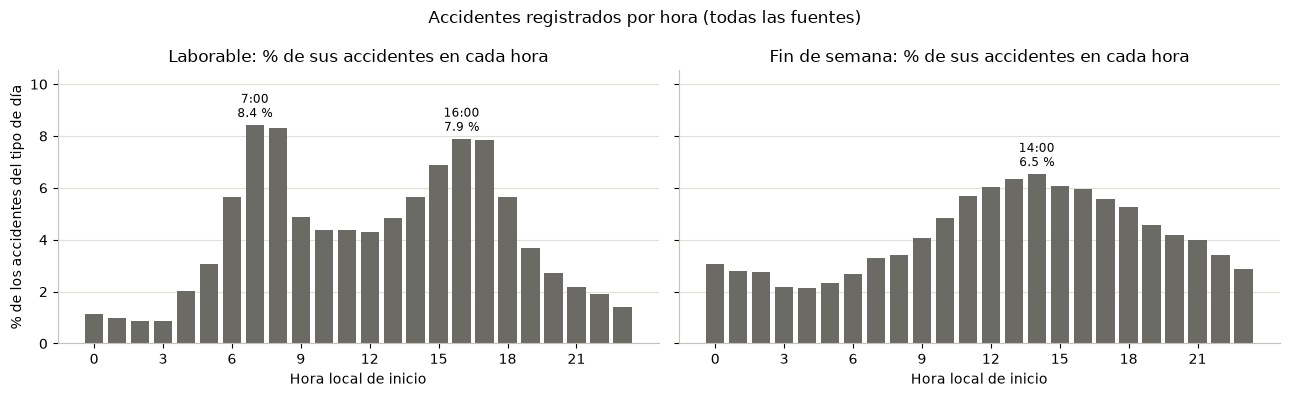

dia_semana,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
% de los accidentes,15.67,16.73,17.04,17.06,17.62,8.64,7.24


In [42]:
# Celda III.2.1: reparto de los accidentes por hora en días laborables y fines de semana (todas las fuentes)
reparto_hora = pd.crosstab(silver["hora"], silver["tipo_dia"], normalize="columns").mul(100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, tipo in zip(axes, ["Laborable", "Fin de semana"]):
    serie = reparto_hora[tipo]
    ax.bar(serie.index, serie.values, color=COLOR_TODAS, width=0.8)
    picos = [serie[:12].idxmax(), serie[12:].idxmax()] if tipo == "Laborable" else [serie.idxmax()]
    for hora in picos:                       # se rotulan solo los picos
        ax.text(hora, serie[hora] + 0.15, f"{hora}:00\n{serie[hora]:.1f} %", ha="center", va="bottom", fontsize=8.5)
    ax.set_title(f"{tipo}: % de sus accidentes en cada hora")
    ax.set_xlabel("Hora local de inicio")
    ax.set_xticks(range(0, 24, 3))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% de los accidentes del tipo de día")
axes[0].set_ylim(0, reparto_hora.values.max() * 1.25)
fig.suptitle("Accidentes registrados por hora (todas las fuentes)")
plt.tight_layout()
guardar_figura(fig, "analisis_01_accidentes_por_hora")
plt.show()

por_dia = silver["dia_semana"].value_counts().reindex(ORDEN_DIAS)
display((por_dia / len(silver) * 100).round(2).to_frame("% de los accidentes").T)

**Interpretación:** en días laborables hay **dos picos**: la mañana (7:00, 8,4 % de los accidentes del día) y la tarde (16:00, 7,9 %), que coinciden con la entrada y salida del trabajo. El fin de semana tiene un **solo pico al mediodía** (14:00, 6,5 %). Cada día laborable concentra entre 15,7 % y 17,6 % de los accidentes; el sábado 8,6 % y el domingo 7,2 %.

Este patrón coincide con lo que reportan los autores del dataset (picos a las 8 y 17 h en días laborables y a las 13 h en fin de semana), con una hora de diferencia. Que **dos análisis independientes encuentren lo mismo** da más confianza en la variable `Start_Time`. Ojo: esto describe **cuántos** accidentes hay, no **cuáles** son de alto impacto.

### III.2.2 ¿Dónde se registran más accidentes de alto impacto?

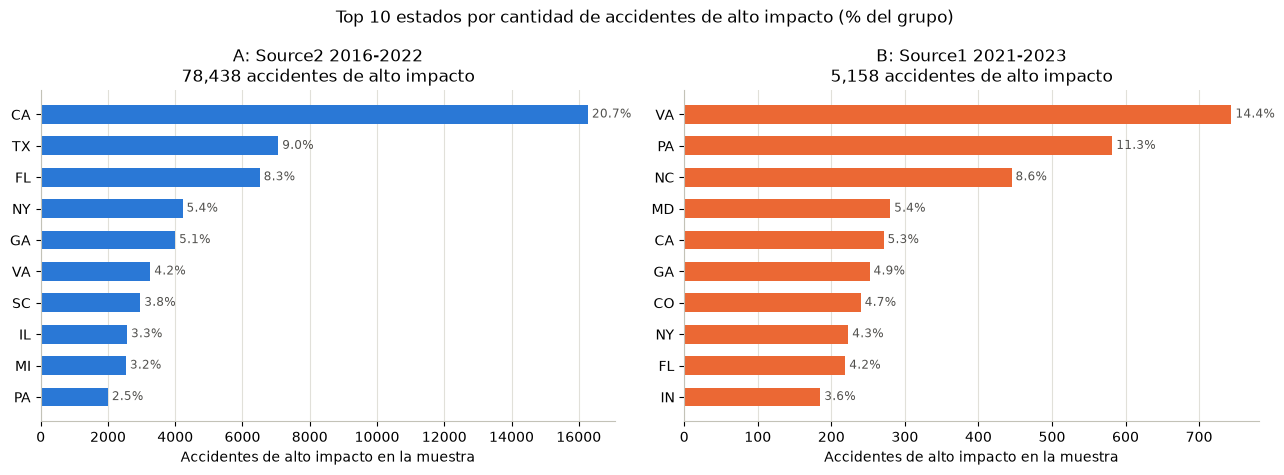

A: Source2 2016-2022: los 3 primeros estados reúnen 38.1% de sus casos de alto impacto
B: Source1 2021-2023: los 3 primeros estados reúnen 34.3% de sus casos de alto impacto


In [43]:
# Celda III.2.2: los 10 estados con más accidentes de alto impacto, dentro de cada grupo
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
top_estados = {}
for ax, grupo in zip(axes, GRUPOS):
    datos = silver[(silver["grupo_severidad"] == grupo) & silver["alto_impacto"]]
    top = datos["State"].value_counts().head(10)
    top_estados[grupo] = top
    ax.barh(top.index, top.values, color=COLORES[grupo], height=0.6)
    for i, v in enumerate(top.values):
        ax.text(v, i, f" {v / len(datos):.1%}", va="center", fontsize=8.5, color="#52514e")
    ax.invert_yaxis()
    ax.set_title(f"{grupo}\n{len(datos):,} accidentes de alto impacto")
    ax.set_xlabel("Accidentes de alto impacto en la muestra")
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 10 estados por cantidad de accidentes de alto impacto (% del grupo)")
plt.tight_layout()
guardar_figura(fig, "analisis_02_top_estados_alto_impacto")
plt.show()

for grupo, top in top_estados.items():
    total = silver[(silver["grupo_severidad"] == grupo) & silver["alto_impacto"]].shape[0]
    print(f"{grupo}: los 3 primeros estados reúnen {top.head(3).sum() / total:.1%} de sus casos de alto impacto")

**Interpretación:** en ambos grupos los casos se concentran en pocos estados (los 3 primeros reúnen **38,1 %** en A y **34,3 %** en B), pero **los estados no son los mismos**: en A lideran California, Texas y Florida; en B, Virginia, Pensilvania y Carolina del Norte. California es el primero en A (20,7 %) y apenas el quinto en B (5,3 %).

Esto muestra que **"dónde" depende de qué fuente se mire**: cada proveedor tiene distinta cobertura en cada estado. Antes de concluir sobre lugares hay que comparar proporciones dentro de cada grupo (sección III.3.3).

### III.2.3 ¿Con qué clima y cerca de qué elementos de la vía ocurren los accidentes?

In [44]:
# Celda III.2.3: distribución del clima (solo clima confiable) y de los elementos de la vía, por grupo
en_grupos = silver[silver["grupo_severidad"].isin(GRUPOS)]
con_clima = en_grupos[en_grupos["clima_confiable"] & en_grupos["clima_grupo"].notna()]

frec_clima = pd.crosstab(con_clima["clima_grupo"], con_clima["grupo_severidad"], normalize="columns").mul(100)
frec_via = en_grupos.groupby("grupo_severidad")[list(ELEMENTOS_VIA)].mean().mul(100).T
frec_via.index = frec_via.index.map(ELEMENTOS_VIA)

print("% de accidentes según el clima (registros con clima confiable)")
display(frec_clima.sort_values(GRUPO_A, ascending=False).round(2))
print("% de accidentes con cada elemento de la vía a poca distancia")
display(frec_via.round(2))

% de accidentes según el clima (registros con clima confiable)


grupo_severidad,A: Source2 2016-2022,B: Source1 2021-2023
clima_grupo,,
Nublado,46.13,36.61
Despejado,41.36,49.52
Lluvia,7.07,6.30
Niebla o humo,2.54,2.68
Nieve o hielo,1.77,3.24
Tormenta,1.10,1.57
Otro,0.02,0.08


% de accidentes con cada elemento de la vía a poca distancia


grupo_severidad,A: Source2 2016-2022,B: Source1 2021-2023
Rampa o salida de autopista,5.06,6.70
Semáforo,22.21,7.46
Cruce peatonal,14.47,8.98
Señal de pare,3.23,2.64


**Interpretación:** la mayoría de los accidentes ocurre con cielo **nublado o despejado** (87 % en A y 86 % en B); la lluvia acompaña a entre 6 % y 7 %, y la nieve o hielo y las tormentas a menos del 4 %. Por eso las condiciones extremas tienen **pocos casos** y sus porcentajes son menos estables.

En la vía aparece una diferencia llamativa: el **22,2 %** de los accidentes de A ocurre cerca de un semáforo, frente a solo **7,5 %** en B. El paper del dataset ya advertía que una fuente reporta más accidentes cerca de intersecciones y la otra más cerca de rampas de autopista. Es decir, **las fuentes no cubren los mismos tipos de calles**, y eso hay que recordarlo al interpretar la sección III.3.5.

---
## III.3 Análisis diagnóstico (nivel 2): ¿con qué se asocia el alto impacto?

Ahora se relacionan **dos o más variables** (análisis bivariado y multivariado): ¿en qué horas, lugares, climas y vías es **más probable** que un accidente sea de alto impacto? Todo se calcula **dentro de cada grupo** y se resume con el índice (sección III.0).

In [45]:
# Celda III.3.0: funciones de apoyo para todo el diagnóstico
def tasa_por_categoria(datos, columna):
    # % de alto impacto de cada categoría, calculado POR SEPARADO en cada grupo comparable
    datos = datos[datos["grupo_severidad"].isin(GRUPOS)]
    tabla = (datos.groupby(["grupo_severidad", columna], observed=True)
                  .agg(accidentes=("ID", "size"), alto_impacto=("alto_impacto", "sum"))
                  .reset_index())
    tabla["pct_alto"] = tabla["alto_impacto"] / tabla["accidentes"] * 100
    promedio_grupo = datos.groupby("grupo_severidad")["alto_impacto"].mean() * 100
    tabla["indice"] = tabla["pct_alto"] / tabla["grupo_severidad"].map(promedio_grupo)
    return tabla


def clasificar(indice_a, indice_b):
    # Lectura prudente: un patrón es "sólido" solo si los DOS grupos coinciden
    alto, bajo = 1 + UMBRAL, 1 - UMBRAL
    if indice_a >= alto and indice_b >= alto:
        return "Sólido: más alto impacto"
    if indice_a <= bajo and indice_b <= bajo:
        return "Sólido: menos alto impacto"
    if (indice_a >= alto and indice_b <= bajo) or (indice_a <= bajo and indice_b >= alto):
        return "Contradictorio"
    return "No concluyente"


def comparar_grupos(datos, columna, variable):
    # Pone lado a lado los grupos A y B y clasifica cada categoría
    tabla = tasa_por_categoria(datos, columna)
    ancho = tabla.pivot(index=columna, columns="grupo_severidad", values=["accidentes", "pct_alto", "indice"])
    resumen = pd.DataFrame({
        "Variable": variable,
        "n A": ancho[("accidentes", GRUPO_A)].fillna(0).astype(int),
        "% alto A": ancho[("pct_alto", GRUPO_A)].round(2),
        "índice A": ancho[("indice", GRUPO_A)].round(2),
        "n B": ancho[("accidentes", GRUPO_B)].fillna(0).astype(int),
        "% alto B": ancho[("pct_alto", GRUPO_B)].round(2),
        "índice B": ancho[("indice", GRUPO_B)].round(2),
    })
    resumen["Lectura"] = [clasificar(a, b) for a, b in zip(resumen["índice A"], resumen["índice B"])]
    poca_muestra = (resumen["n A"] < MUESTRA_MINIMA) | (resumen["n B"] < MUESTRA_MINIMA)
    resumen.loc[poca_muestra, "Lectura"] = "Muestra insuficiente"
    return resumen.rename_axis("Categoría").reset_index()


def grafico_indices(tabla, titulo, nombre_archivo):
    # Barras horizontales del índice de A y B para cada categoría (línea en 1 = promedio del grupo)
    tabla = tabla[tabla["Lectura"] != "Muestra insuficiente"].reset_index(drop=True)
    y = np.arange(len(tabla))
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(tabla) + 1.8))
    for desplazamiento, grupo, col in [(-0.2, GRUPO_A, "índice A"), (0.2, GRUPO_B, "índice B")]:
        ax.barh(y + desplazamiento, tabla[col], height=0.38, color=COLORES[grupo], label=grupo,
                edgecolor="white", linewidth=2)
    ax.axvline(1, color="#52514e", linewidth=1)
    ax.set_yticks(y, [f"{c}\n({l})" for c, l in zip(tabla["Categoría"], tabla["Lectura"])], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("Índice de alto impacto (1 = promedio de su grupo)")
    ax.set_title(titulo)
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    guardar_figura(fig, nombre_archivo)
    plt.show()

### III.3.1 La trampa de mezclar fuentes

¿Qué pasaría si se calculara el % de alto impacto de cada año **sin controlar la fuente**?

,Todas las fuentes mezcladas,A: Source2 2016-2022,B: Source1 2021-2023,% registros de Source1
anio,,,,
2017,35.8,36.6,NaN,23.8
2018,35.6,35.9,NaN,18.6
2019,27.9,30.4,NaN,27.5
2020,18.4,30.5,NaN,59.8
2021,11.5,34.2,2.5,70.9
2022,6.8,34.1,2.6,86.4


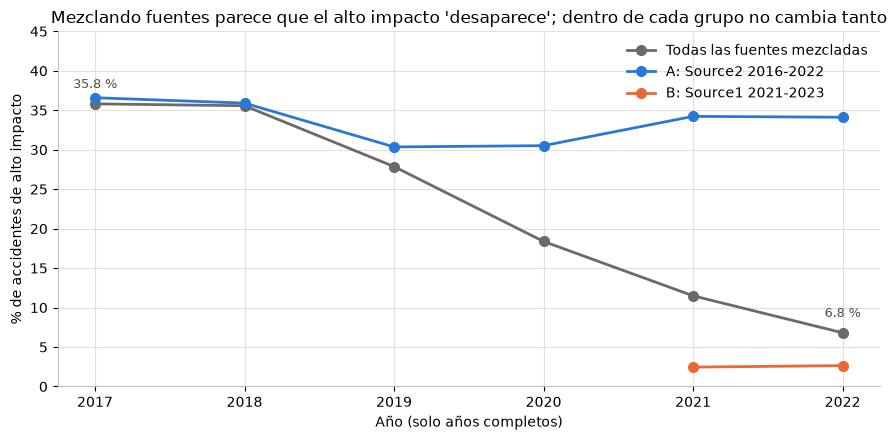

In [46]:
# Celda III.3.1: % de alto impacto por año: todas las fuentes mezcladas frente a cada grupo (solo años completos)
completos = silver[silver["anio_completo"]]
mezcla = completos.groupby("anio")["alto_impacto"].mean().mul(100).rename("Todas las fuentes mezcladas")
por_grupo_anio = (completos[completos["grupo_severidad"].isin(GRUPOS)]
                  .groupby(["anio", "grupo_severidad"])["alto_impacto"].mean().mul(100).unstack())
peso_source1 = completos.groupby("anio")["Source"].apply(lambda s: (s == "Source1").mean() * 100)
display(pd.concat([mezcla, por_grupo_anio, peso_source1.rename("% registros de Source1")], axis=1).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mezcla.index, mezcla.values, marker="o", markersize=7, linewidth=2, color=COLOR_TODAS, label=mezcla.name)
for grupo in GRUPOS:
    serie = por_grupo_anio[grupo].dropna()
    ax.plot(serie.index, serie.values, marker="o", markersize=7, linewidth=2, color=COLORES[grupo], label=grupo)
ax.text(mezcla.index[0], mezcla.iloc[0] + 2, f"{mezcla.iloc[0]:.1f} %", ha="center", fontsize=9, color="#52514e")
ax.text(mezcla.index[-1], mezcla.iloc[-1] + 2, f"{mezcla.iloc[-1]:.1f} %", ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, 45)
ax.set_xlabel("Año (solo años completos)")
ax.set_ylabel("% de accidentes de alto impacto")
ax.set_title("Mezclando fuentes parece que el alto impacto 'desaparece'; dentro de cada grupo no cambia tanto")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
guardar_figura(fig, "analisis_03_trampa_mezclar_fuentes")
plt.show()

**Interpretación: por qué no se puede mezclar fuentes**

- Si se mezclan todas las fuentes, el alto impacto parece **caer de 35,8 % (2017) a 6,8 % (2022)**. Alguien podría concluir que "los accidentes ya no colapsan el tráfico".
- Pero dentro del grupo **A** el porcentaje se mantiene (36,6 % → 34,1 %) y dentro de **B** también (2,5 % → 2,6 %).
- La "caída" se explica porque **Source1 pasó de ser el 23,8 % de los registros (2017) al 86,4 % (2022)**, y Source1 usa hoy un criterio que casi nunca asigna alto impacto. Cambió **quién registra**, no necesariamente el tráfico.

Este es un ejemplo de la **paradoja de Simpson** vista en clase: un promedio global que mezcla grupos distintos puede contar una historia falsa. Es el hallazgo más importante para la **dimensión de consistencia**.

### III.3.2 Sub-pregunta 1 — Tiempo: ¿a qué hora es más probable el alto impacto?

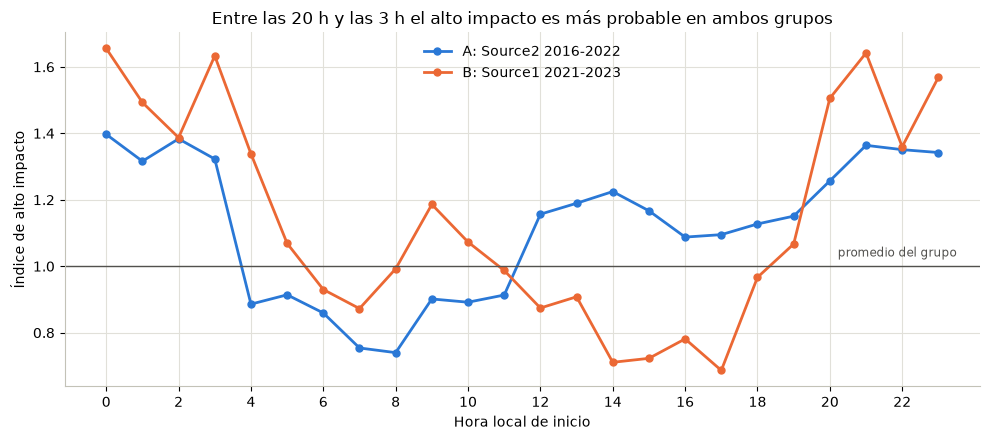

Horas con índice ≥ 1.10 en AMBOS grupos: [0, 1, 2, 3, 20, 21, 22, 23]


In [47]:
# Celda III.3.2: índice de alto impacto por hora en cada grupo
por_hora = tasa_por_categoria(silver, "hora")

fig, ax = plt.subplots(figsize=(10, 4.5))
for grupo in GRUPOS:
    serie = por_hora[por_hora["grupo_severidad"] == grupo]
    ax.plot(serie["hora"], serie["indice"], marker="o", markersize=5, linewidth=2, color=COLORES[grupo], label=grupo)
ax.axhline(1, color="#52514e", linewidth=1)
ax.text(23.5, 1.02, "promedio del grupo", ha="right", va="bottom", fontsize=8.5, color="#52514e")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora local de inicio")
ax.set_ylabel("Índice de alto impacto")
ax.set_title("Entre las 20 h y las 3 h el alto impacto es más probable en ambos grupos")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
guardar_figura(fig, "analisis_04_indice_por_hora")
plt.show()

indice_hora = por_hora.pivot(index="hora", columns="grupo_severidad", values="indice")
horas_solidas = indice_hora[(indice_hora[GRUPO_A] >= 1 + UMBRAL) & (indice_hora[GRUPO_B] >= 1 + UMBRAL)].index.tolist()
print(f"Horas con índice ≥ {1 + UMBRAL:.2f} en AMBOS grupos: {horas_solidas}")

In [48]:
# Celda III.3.3: franja horaria, tipo de día y luz, con su lectura de solidez
tiempo = pd.concat([
    comparar_grupos(silver, "franja_horaria", "Franja horaria"),
    comparar_grupos(silver, "tipo_dia", "Tipo de día"),
    comparar_grupos(silver[silver["Sunrise_Sunset"].notna()], "Sunrise_Sunset", "Luz (Day/Night)"),
], ignore_index=True)
tiempo

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,06-10 Punta mañana,Franja horaria,78235,26.95,0.80,35735,2.55,0.98,No concluyente
1,10-15 Mediodía,Franja horaria,53946,35.91,1.06,52855,2.29,0.88,No concluyente
2,15-19 Punta tarde,Franja horaria,58186,37.83,1.12,60116,2.00,0.77,Contradictorio
3,19-22 Noche,Franja horaria,18514,41.76,1.23,19935,3.57,1.38,Sólido: más alto impacto
4,22-06 Madrugada,Franja horaria,22493,36.61,1.08,30608,3.66,1.41,No concluyente
5,Fin de semana,Tipo de día,23483,57.17,1.69,44327,2.80,1.08,No concluyente
6,Laborable,Tipo de día,207891,31.27,0.92,154922,2.53,0.98,No concluyente
7,Day,Luz (Day/Night),171081,33.12,0.98,133378,2.15,0.85,No concluyente
8,Night,Luz (Day/Night),60174,36.09,1.06,64374,3.27,1.30,No concluyente


**Interpretación del tiempo**

- **Por hora (gráfico):** entre las **20 h y las 3 h** ambos grupos superan en al menos 10 % su promedio (índices de 1,26 a 1,66). En cambio, las **7–8 h** (punta de la mañana) quedan **en el promedio o por debajo** en ambos grupos (A: 0,74–0,75; B: 0,87–0,99): hay muchos accidentes, pero una menor proporción se vuelve de alto impacto.
- **Por franja:** solo la **noche (19–22 h)** es **sólida**: índice **1,23 en A y 1,38 en B**. La madrugada (22–06 h) sale "no concluyente" porque en A incluye las 4–5 h, que están bajo el promedio; la franja esconde parte del patrón por hora.
- **La punta de la tarde (15–19 h) es contradictoria:** en A está sobre el promedio (1,12) y en B por debajo (0,77). No se puede afirmar nada sobre ella.
- **Fin de semana y noche (Day/Night):** ambos grupos van en la misma dirección (más alto impacto el fin de semana y de noche), pero en uno de los dos la diferencia es pequeña (B: 1,08 el fin de semana; A: 1,06 de noche). Quedan como **no concluyentes**.

### III.3.3 Sub-pregunta 2 — Lugar: ¿coinciden las dos fuentes en qué estados tienen más alto impacto?

Estados con al menos 500 accidentes en ambos grupos: 29
Correlación de Spearman entre el % de alto impacto de A y de B: 0.43
Lectura
Sólido: más alto impacto      11
Contradictorio                 7
No concluyente                 6
Sólido: menos alto impacto     5


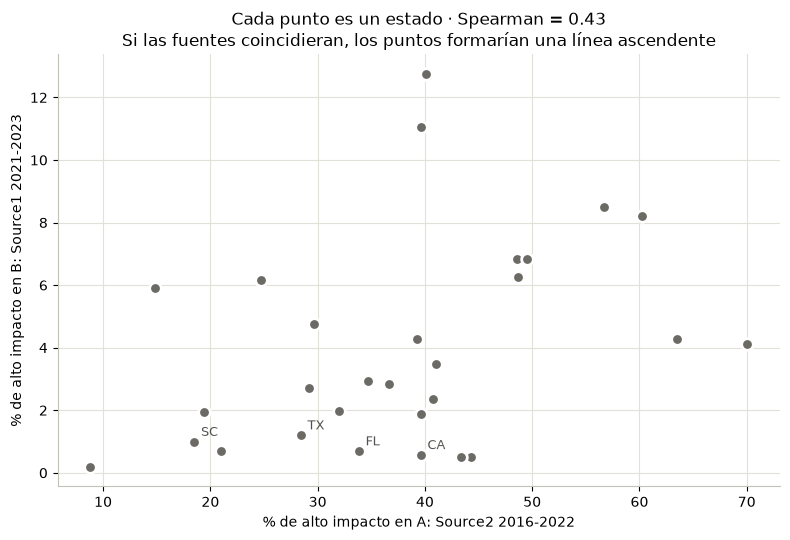

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
3,CA,Estado,41099,39.59,1.17,46888,0.58,0.22,Contradictorio
41,TX,Estado,24865,28.41,0.84,10477,1.21,0.47,Sólido: menos alto impacto
8,FL,Estado,19254,33.82,1.00,31378,0.70,0.27,No concluyente
38,SC,Estado,16021,18.48,0.55,8484,1.00,0.39,Sólido: menos alto impacto
25,NC,Estado,12548,14.81,0.44,7539,5.90,2.28,Contradictorio
32,NY,Estado,10345,40.77,1.20,9488,2.35,0.91,No concluyente
36,PA,Estado,8089,24.70,0.73,9453,6.16,2.38,Contradictorio
12,IL,Estado,6997,36.67,1.08,1796,2.84,1.10,No concluyente
43,VA,Estado,6716,48.54,1.43,10896,6.83,2.64,Sólido: más alto impacto
9,GA,Estado,6633,60.26,1.78,3069,8.21,3.17,Sólido: más alto impacto


In [49]:
# Celda III.3.4: % de alto impacto por estado en A frente a B (solo estados con muestra suficiente en ambos)
por_estado = comparar_grupos(silver, "State", "Estado")
comparables = por_estado[por_estado["Lectura"] != "Muestra insuficiente"]
rho_estados = comparables["% alto A"].corr(comparables["% alto B"], method="spearman")

print(f"Estados con al menos {MUESTRA_MINIMA} accidentes en ambos grupos: {len(comparables)}")
print(f"Correlación de Spearman entre el % de alto impacto de A y de B: {rho_estados:.2f}")
print(comparables["Lectura"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(comparables["% alto A"], comparables["% alto B"], s=70, color=COLOR_TODAS, edgecolor="white", linewidth=2)
for _, fila in comparables.nlargest(4, "n A").iterrows():       # se rotulan solo los 4 estados más grandes
    ax.annotate(fila["Categoría"], (fila["% alto A"], fila["% alto B"]), xytext=(5, 4),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel(f"% de alto impacto en {GRUPO_A}")
ax.set_ylabel(f"% de alto impacto en {GRUPO_B}")
ax.set_title(f"Cada punto es un estado · Spearman = {rho_estados:.2f}\nSi las fuentes coincidieran, los puntos formarían una línea ascendente")
plt.tight_layout()
guardar_figura(fig, "analisis_05_estados_A_vs_B")
plt.show()

comparables.sort_values("n A", ascending=False).head(10)

**Interpretación del lugar**

- Entre los **29 estados** con muestra suficiente en ambos grupos, la correlación de Spearman entre el % de alto impacto de A y de B es **0,43**: el orden de los estados **coincide poco** (1 sería el mismo orden).
- Algunos estados sí coinciden: **Georgia y Virginia** están sobre el promedio en ambos grupos; **Texas y Carolina del Sur**, por debajo.
- Pero el estado con más accidentes, **California, se contradice**: índice **1,17 en A** y **0,22 en B**. Lo mismo ocurre con Carolina del Norte y Pensilvania (7 estados contradictorios en total).

**Lectura prudente:** con estos datos **no se puede construir un ranking confiable de "estados con más colapsos"**; el resultado cambia según la fuente. La sub-pregunta 2 solo se responde en términos de **cantidad de casos dentro de cada fuente** (sección III.2.2).

### III.3.4 Sub-pregunta 3 — Clima: ¿con qué condiciones aumenta la proporción de alto impacto?

Solo se usan los registros con **clima confiable** (medido a máximo 1 h del accidente; dimensión de exactitud).

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,Despejado,Clima,92904,31.39,0.93,95252,2.47,0.98,No concluyente
1,Lluvia,Clima,15881,39.68,1.18,12114,2.42,0.96,No concluyente
2,Niebla o humo,Clima,5714,28.88,0.86,5156,1.78,0.71,Sólido: menos alto impacto
3,Nieve o hielo,Clima,3982,44.02,1.31,6235,3.58,1.42,Sólido: más alto impacto
4,Nublado,Clima,103615,34.52,1.02,70419,2.59,1.03,No concluyente
5,Otro,Clima,51,47.06,1.40,150,2.67,1.06,Muestra insuficiente
6,Tormenta,Clima,2464,41.60,1.23,3020,2.02,0.80,Contradictorio
7,Muy reducida (<1 mi),Visibilidad,3173,31.58,0.94,3408,2.88,1.14,No concluyente
8,Reducida (1-5 mi),Visibilidad,15050,36.98,1.10,13050,2.56,1.01,No concluyente
9,Normal (>=5 mi),Visibilidad,206388,33.49,0.99,175678,2.51,1.00,No concluyente


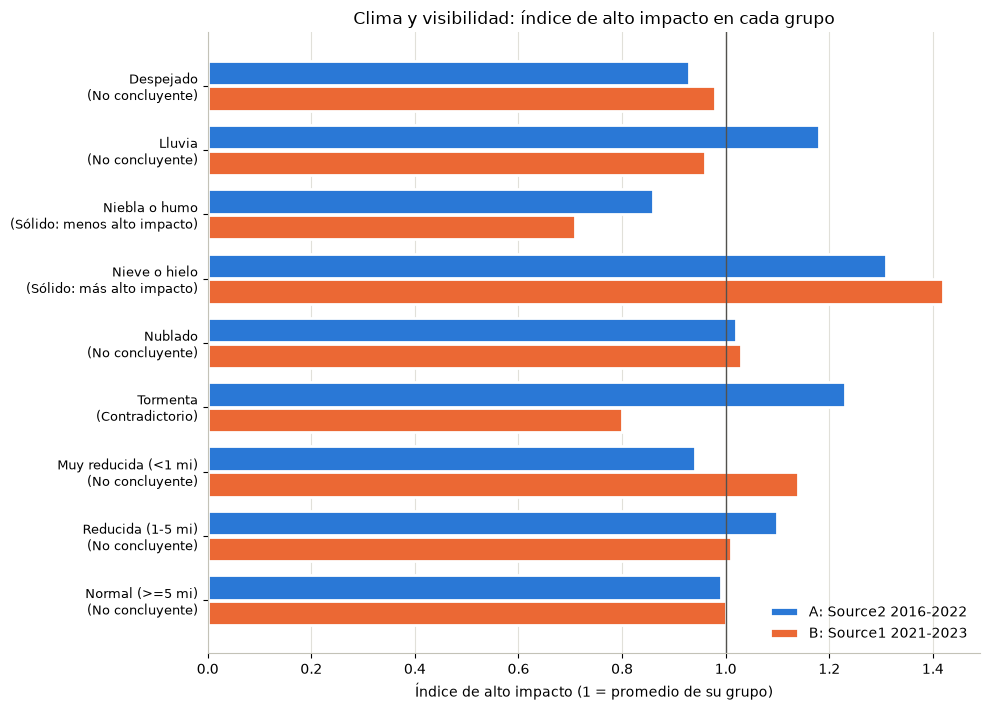

In [50]:
# Celda III.3.5: clima agrupado y visibilidad
con_visibilidad = en_grupos[en_grupos["clima_confiable"] & en_grupos["visibilidad_grupo"].notna()]
clima = pd.concat([
    comparar_grupos(con_clima, "clima_grupo", "Clima"),
    comparar_grupos(con_visibilidad, "visibilidad_grupo", "Visibilidad"),
], ignore_index=True)
display(clima)
grafico_indices(clima, "Clima y visibilidad: índice de alto impacto en cada grupo", "analisis_06_indice_clima")

**Interpretación del clima**

- **Nieve o hielo** es el único clima **sólido con más alto impacto**: índice **1,31 en A y 1,42 en B**.
- **Niebla o humo** es **sólido con menos alto impacto** (0,86 y 0,71). Es contraintuitivo; una posible explicación (hipótesis, no comprobada) es que con niebla se conduce más despacio o hay menos tráfico.
- **Lluvia** sube en A (1,18) pero no en B (0,96): **no concluyente**. **Tormenta** es **contradictoria** (1,23 frente a 0,80).
- **Visibilidad:** ningún rango muestra un patrón común. Recordar que el sensor suele reportar como máximo 10 millas (sección I.6.1), así que esta variable distingue poco.

### III.3.5 Sub-pregunta 4 — Vía: ¿qué elementos cercanos acompañan al alto impacto?

Para cada elemento se compara el % de alto impacto de los accidentes **con** ese elemento cerca frente al promedio del grupo.

,Categoría,Variable,n A,% alto A,índice A,n B,% alto B,índice B,Lectura
0,Rampa o salida de autopista,Elemento de la vía,11717,57.61,1.70,13342,3.11,1.20,Sólido: más alto impacto
1,Semáforo,Elemento de la vía,51386,9.28,0.27,14873,3.10,1.20,Contradictorio
2,Cruce peatonal,Elemento de la vía,33489,7.41,0.22,17901,1.56,0.60,Sólido: menos alto impacto
3,Señal de pare,Elemento de la vía,7474,4.94,0.15,5264,2.89,1.12,Contradictorio


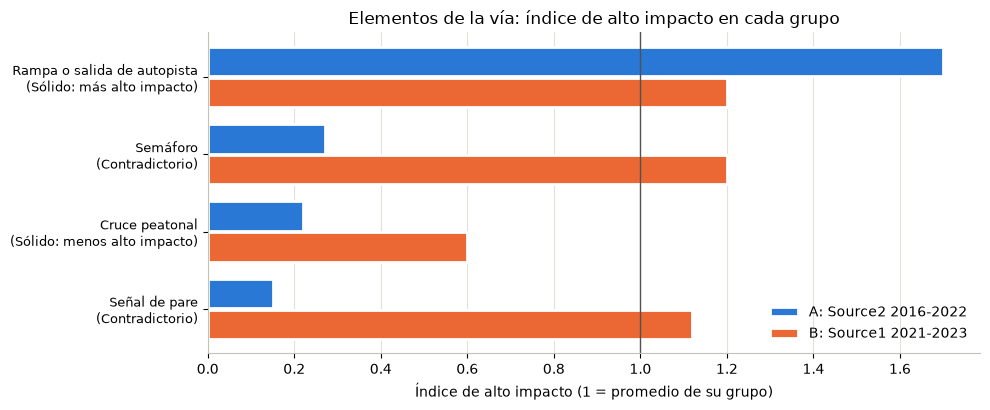

In [51]:
# Celda III.3.6: elementos de la vía (filas = accidentes CON el elemento a poca distancia)
filas_via = []
for columna, nombre in ELEMENTOS_VIA.items():
    cerca = silver[columna].map({True: nombre, False: "Sin el elemento"})
    resumen = comparar_grupos(silver.assign(cerca=cerca), "cerca", "Elemento de la vía")
    filas_via.append(resumen[resumen["Categoría"] == nombre])
via = pd.concat(filas_via, ignore_index=True)
display(via)
grafico_indices(via, "Elementos de la vía: índice de alto impacto en cada grupo", "analisis_07_indice_via")

**Interpretación de la vía**

- **Rampas, salidas o entradas de autopista** (`Junction`): **sólido, más alto impacto** (índice **1,70 en A** y **1,20 en B**). Un accidente en una vía rápida tiende a afectar más el flujo.
- **Cruce peatonal:** **sólido, menos alto impacto** (0,22 y 0,60): son lugares de calle urbana, donde el tráfico ya va lento.
- **Semáforo y señal de pare** son **contradictorios**: en A tienen muy poco alto impacto (0,27 y 0,15) y en B un poco más que el promedio (1,20 y 1,12). Como vimos en 2.3, las fuentes cubren distintos tipos de calles, así que no se puede concluir nada sobre estos elementos.

### III.3.6 Análisis multivariado: ¿los patrones se mantienen al combinar variables?

Un patrón puede ser engañoso si en realidad se debe a otra variable (por ejemplo, que los accidentes en rampas de autopista ocurran a otras horas). Por eso se combinan variables:
1. **Franja horaria × día de la semana** (mapa de calor del índice).
2. **Rampa de autopista × franja horaria**: ¿el mayor alto impacto en rampas aparece en todas las franjas?

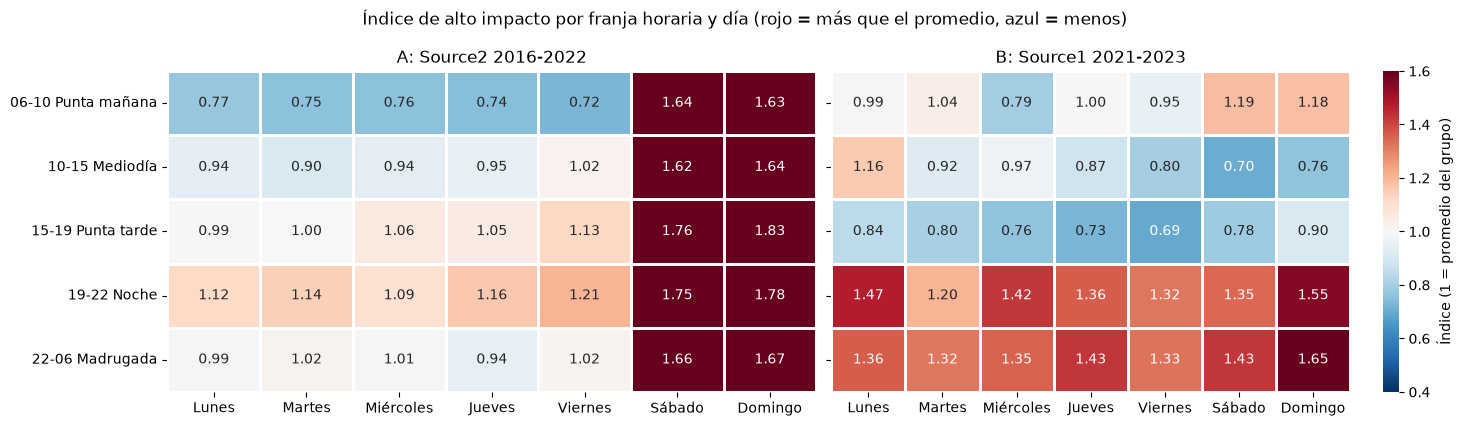

In [52]:
# Celda III.3.7: mapa de calor franja × día de la semana (índice dentro de cada grupo)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, grupo in zip(axes, GRUPOS):
    datos = silver[silver["grupo_severidad"] == grupo]
    tabla = datos.pivot_table(index="franja_horaria", columns="dia_semana", values="alto_impacto", aggfunc="mean")
    tabla = (tabla / datos["alto_impacto"].mean()).reindex(index=ORDEN_FRANJAS, columns=ORDEN_DIAS)
    sns.heatmap(tabla, ax=ax, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6,
                linewidths=2, linecolor="white", cbar=(grupo == GRUPO_B),
                cbar_kws={"label": "Índice (1 = promedio del grupo)"})
    ax.set_title(grupo)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Índice de alto impacto por franja horaria y día (rojo = más que el promedio, azul = menos)")
plt.tight_layout()
guardar_figura(fig, "analisis_08_mapa_calor_franja_dia")
plt.show()

In [53]:
# Celda III.3.8: ¿el patrón de las rampas de autopista se mantiene en cada franja horaria?
rampa_franja = (en_grupos.pivot_table(index="franja_horaria", columns=["grupo_severidad", "Junction"],
                                      values="alto_impacto", aggfunc="mean").mul(100).reindex(ORDEN_FRANJAS))
veces_mas = pd.DataFrame({
    f"{grupo}: con rampa / sin rampa": rampa_franja[(grupo, True)] / rampa_franja[(grupo, False)]
    for grupo in GRUPOS
}).round(2)
veces_mas

,A: Source2 2016-2022: con rampa / sin rampa,B: Source1 2021-2023: con rampa / sin rampa
franja_horaria,,
06-10 Punta mañana,2.01,1.06
10-15 Mediodía,1.77,1.07
15-19 Punta tarde,1.65,1.18
19-22 Noche,1.59,1.51
22-06 Madrugada,1.57,1.29


**Interpretación del análisis multivariado**

- **Mapa de calor:** en A el fin de semana está sobre el promedio en **todas** las franjas (1,62 a 1,83), mientras que en B el fin de semana casi no se distingue. Lo que **sí se repite en los dos mapas** es la **noche (19–22 h)**: está sobre el promedio en **los 7 días de ambos grupos** (de 1,09 a 1,78). Esto refuerza el hallazgo de la sección III.3.2.
- **Rampas por franja:** en A, un accidente cerca de una rampa tiene entre **1,57 y 2,01 veces** más proporción de alto impacto que uno lejos de ella, en las 5 franjas. En B la razón es mayor que 1 en todas las franjas (1,06 a 1,51), aunque de día es pequeña. Por lo tanto, el patrón de las rampas **no se explica solo por la hora** del accidente.

### III.3.7 Matriz de solidez: resumen del diagnóstico

Se juntan todos los patrones evaluados. **Solo los "sólidos" se usarán para recomendar**; los demás quedan como preguntas abiertas.

In [54]:
# Celda III.3.9: matriz de solidez (todas las comparaciones en una tabla)
matriz = pd.concat([tiempo, clima, via], ignore_index=True)
matriz = matriz[matriz["Lectura"] != "Muestra insuficiente"]

with pd.option_context("display.max_rows", 60):
    display(matriz[["Variable", "Categoría", "índice A", "índice B", "Lectura"]])
print(matriz["Lectura"].value_counts().to_string())

,Variable,Categoría,índice A,índice B,Lectura
0,Franja horaria,06-10 Punta mañana,0.80,0.98,No concluyente
1,Franja horaria,10-15 Mediodía,1.06,0.88,No concluyente
2,Franja horaria,15-19 Punta tarde,1.12,0.77,Contradictorio
3,Franja horaria,19-22 Noche,1.23,1.38,Sólido: más alto impacto
4,Franja horaria,22-06 Madrugada,1.08,1.41,No concluyente
5,Tipo de día,Fin de semana,1.69,1.08,No concluyente
6,Tipo de día,Laborable,0.92,0.98,No concluyente
7,Luz (Day/Night),Day,0.98,0.85,No concluyente
8,Luz (Day/Night),Night,1.06,1.30,No concluyente
9,Clima,Despejado,0.93,0.98,No concluyente


Lectura
No concluyente                13
Contradictorio                 4
Sólido: más alto impacto       3
Sólido: menos alto impacto     2


**Interpretación de la matriz:** de **22 patrones** evaluados, solo **5 son sólidos** (23 %):

| Más alto impacto en ambos grupos | Menos alto impacto en ambos grupos |
|---|---|
| Noche 19–22 h · Nieve o hielo · Rampa o salida de autopista | Niebla o humo · Cruce peatonal |

Hay **4 contradictorios** (punta de la tarde, tormenta, semáforo, señal de pare) y **13 no concluyentes**. Esto confirma por qué no se deben dar por ciertos los resultados de una sola fuente: **la mayoría de los patrones que parecen claros en un grupo no se repiten en el otro**.

---
## III.4 Análisis prescriptivo (nivel 4): ¿qué conviene hacer?

Para decidir dónde poner recursos hay que distinguir dos cosas que **no son lo mismo**:

- **Cantidad:** ¿en qué franja ocurren **más** accidentes de alto impacto? → sirve para **dimensionar** equipos (cuántas grúas o patrullas).
- **Proporción:** ¿en qué franja un accidente tiene **más probabilidad** de ser de alto impacto? → sirve para **priorizar la respuesta** (protocolos de despeje rápido).

Como las franjas no duran lo mismo (la madrugada dura 8 horas y la noche solo 3), la cantidad se divide entre las horas de cada franja.

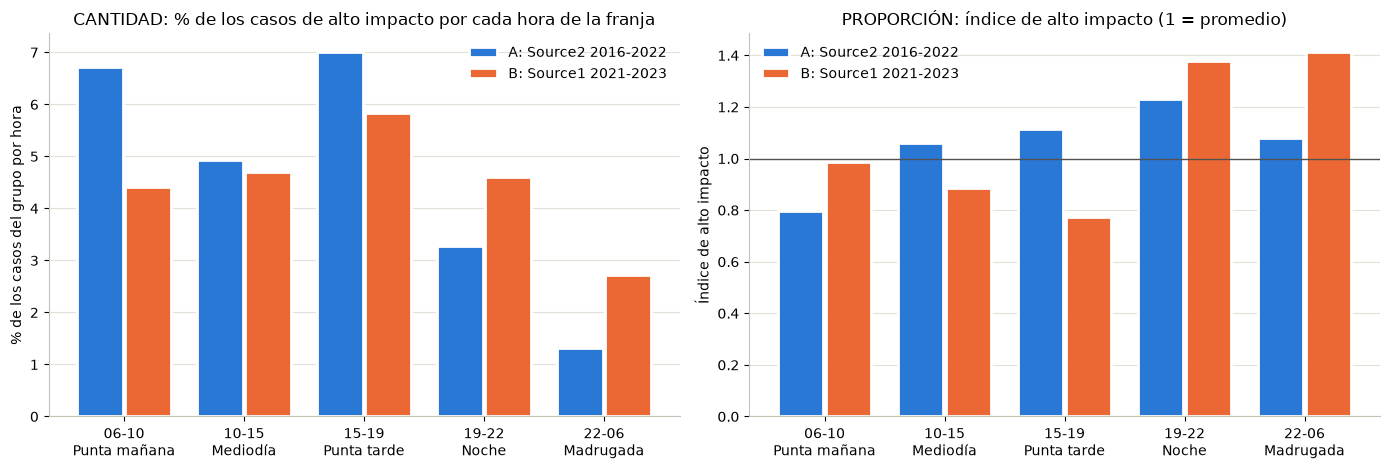

% de casos por hora de franja                                    indice                     
grupo_severidad             A: Source2 2016-2022 B: Source1 2021-2023 A: Source2 2016-2022 B: Source1 2021-2023
franja_horaria                                                                                                 
06-10 Punta mañana                          6.72                 4.42                 0.80                 0.98
10-15 Mediodía                              4.94                 4.69                 1.06                 0.88
15-19 Punta tarde                           7.02                 5.84                 1.12                 0.77
19-22 Noche                                 3.29                 4.60                 1.23                 1.38
22-06 Madrugada                             1.31                 2.72                 1.08                 1.41

In [55]:
# Celda III.4.1: cantidad (casos por hora de franja) frente a proporción (índice) en cada franja
franjas = tasa_por_categoria(silver, "franja_horaria")
franjas["% de los casos de alto impacto"] = (franjas["alto_impacto"]
                                             / franjas.groupby("grupo_severidad")["alto_impacto"].transform("sum") * 100)
franjas["% de casos por hora de franja"] = franjas["% de los casos de alto impacto"] / franjas["franja_horaria"].map(HORAS_FRANJA)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(ORDEN_FRANJAS))
for desplazamiento, grupo in [(-0.2, GRUPO_A), (0.2, GRUPO_B)]:
    d = franjas[franjas["grupo_severidad"] == grupo].set_index("franja_horaria").reindex(ORDEN_FRANJAS)
    axes[0].bar(x + desplazamiento, d["% de casos por hora de franja"], width=0.38, color=COLORES[grupo],
                label=grupo, edgecolor="white", linewidth=2)
    axes[1].bar(x + desplazamiento, d["indice"], width=0.38, color=COLORES[grupo],
                label=grupo, edgecolor="white", linewidth=2)
axes[0].set_title("CANTIDAD: % de los casos de alto impacto por cada hora de la franja")
axes[0].set_ylabel("% de los casos del grupo por hora")
axes[1].set_title("PROPORCIÓN: índice de alto impacto (1 = promedio)")
axes[1].set_ylabel("Índice de alto impacto")
axes[1].axhline(1, color="#52514e", linewidth=1)
for ax, posicion in zip(axes, ["upper right", "upper left"]):
    ax.set_xticks(x, [f.replace(" ", "\n", 1) for f in ORDEN_FRANJAS])
    ax.legend(frameon=False, loc=posicion)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar_figura(fig, "analisis_09_cantidad_vs_proporcion")
plt.show()

(franjas.pivot(index="franja_horaria", columns="grupo_severidad",
               values=["% de casos por hora de franja", "indice"]).reindex(ORDEN_FRANJAS).round(2))

**Interpretación: cantidad no es lo mismo que proporción**

- **Cantidad:** la **punta de la tarde (15–19 h)** concentra la mayor cantidad de casos de alto impacto por hora en **ambos** grupos (**7,0 %** por hora en A y **5,8 %** en B). La madrugada tiene la menor cantidad por hora en ambos.
- **Proporción:** en A la probabilidad más alta está en la **noche (19–22 h, índice 1,23)**; en B, en la madrugada (1,41) y la noche (1,38). La noche es la **única franja alta en ambos grupos**, y la punta de la tarde, con más casos, tiene en B una proporción baja (0,77).
- Las dos lecturas llevan a **decisiones distintas**: más equipos donde hay **más casos** (tarde) y protocolos de respuesta rápida donde un accidente tiene **más probabilidad** de colapsar el tráfico (noche).

In [56]:
# Celda III.4.2: recomendaciones, cada una con su evidencia, su solidez y lo que falta validar
def evidencia(categoria):
    fila = matriz[matriz["Categoría"] == categoria].iloc[0]
    return f"índice A = {fila['índice A']:.2f} · B = {fila['índice B']:.2f} ({fila['Lectura']})"


cant = franjas.pivot(index="franja_horaria", columns="grupo_severidad", values="% de casos por hora de franja")
recomendaciones = pd.DataFrame([
    ("Dimensionar grúas, patrullas y ambulancias con más turnos en la punta de la tarde (15–19 h)",
     f"Franja con más casos de alto impacto por hora en ambos grupos: A = {cant.loc['15-19 Punta tarde', GRUPO_A]:.1f} %/h · "
     f"B = {cant.loc['15-19 Punta tarde', GRUPO_B]:.1f} %/h",
     "Alta", "Contrastar con los registros propios del departamento de transporte de cada estado", "Departamento de transporte"),
    ("Mantener protocolos de despeje rápido en la noche (19–22 h), aunque haya menos accidentes",
     "19-22 Noche: " + evidencia("19-22 Noche"),
     "Media", "Medir el tiempo real de respuesta nocturno; el dataset no tiene volumen de tráfico", "Policía de tránsito / emergencias"),
    ("Priorizar el despeje rápido de accidentes en rampas, salidas y entradas de autopista",
     "Rampa: " + evidencia("Rampa o salida de autopista") + "; se mantiene en las 5 franjas (celda III.3.8)",
     "Media", "Confirmar con un registro de tipo de vía más preciso que la cercanía en OpenStreetMap", "Departamento de transporte"),
    ("Activar protocolos especiales cuando hay nieve o hielo",
     "Nieve o hielo: " + evidencia("Nieve o hielo"),
     "Media", "Pocos casos (≈ 2–3 % de los accidentes); revisar por estado con datos locales de clima", "Departamento de transporte"),
    ("No asignar recursos por estado según el % de alto impacto mientras la severidad no tenga un criterio común",
     f"El ranking de estados de A y B casi no coincide (Spearman = {rho_estados:.2f})",
     "Alta (es una regla de calidad)", "Usar conteos dentro de una misma fuente, nunca porcentajes que mezclen fuentes", "Equipo de análisis"),
    ("Documentar y unificar el criterio de severidad de cada fuente y año",
     "Source1 pasó de ~33 % a < 3 % de alto impacto y dejó de usar el nivel 3 (sección II.6)",
     "Alta (gobierno de datos)", "Pedir al mantenedor la definición de severidad por fuente", "Mantenedor del dataset / proveedores"),
    ("No tomar decisiones sobre lluvia, tormenta, semáforos o señales de pare con estos datos",
     "Lluvia: " + evidencia("Lluvia") + " · Semáforo: " + evidencia("Semáforo"),
     "—", "Requiere datos de volumen de tráfico y de lluvia más completos (precipitación tenía 28,58 % de nulos)", "Equipo de análisis"),
], columns=["Recomendación (propuesta, no certeza)", "Evidencia", "Solidez", "Qué falta validar antes de aplicarla", "Responsable sugerido"])

with pd.option_context("display.max_colwidth", None):
    display(recomendaciones)

,"Recomendación (propuesta, no certeza)",Evidencia,Solidez,Qué falta validar antes de aplicarla,Responsable sugerido
0,"Dimensionar grúas, patrullas y ambulancias con más turnos en la punta de la tarde (15–19 h)",Franja con más casos de alto impacto por hora en ambos grupos: A = 7.0 %/h · B = 5.8 %/h,Alta,Contrastar con los registros propios del departamento de transporte de cada estado,Departamento de transporte
1,"Mantener protocolos de despeje rápido en la noche (19–22 h), aunque haya menos accidentes",19-22 Noche: índice A = 1.23 · B = 1.38 (Sólido: más alto impacto),Media,Medir el tiempo real de respuesta nocturno; el dataset no tiene volumen de tráfico,Policía de tránsito / emergencias
2,"Priorizar el despeje rápido de accidentes en rampas, salidas y entradas de autopista",Rampa: índice A = 1.70 · B = 1.20 (Sólido: más alto impacto); se mantiene en las 5 franjas (celda III.3.8),Media,Confirmar con un registro de tipo de vía más preciso que la cercanía en OpenStreetMap,Departamento de transporte
3,Activar protocolos especiales cuando hay nieve o hielo,Nieve o hielo: índice A = 1.31 · B = 1.42 (Sólido: más alto impacto),Media,Pocos casos (≈ 2–3 % de los accidentes); revisar por estado con datos locales de clima,Departamento de transporte
4,No asignar recursos por estado según el % de alto impacto mientras la severidad no tenga un criterio común,El ranking de estados de A y B casi no coincide (Spearman = 0.43),Alta (es una regla de calidad),"Usar conteos dentro de una misma fuente, nunca porcentajes que mezclen fuentes",Equipo de análisis
5,Documentar y unificar el criterio de severidad de cada fuente y año,Source1 pasó de ~33 % a < 3 % de alto impacto y dejó de usar el nivel 3 (sección II.6),Alta (gobierno de datos),Pedir al mantenedor la definición de severidad por fuente,Mantenedor del dataset / proveedores
6,"No tomar decisiones sobre lluvia, tormenta, semáforos o señales de pare con estos datos",Lluvia: índice A = 1.18 · B = 0.96 (No concluyente) · Semáforo: índice A = 0.27 · B = 1.20 (Contradictorio),—,"Requiere datos de volumen de tráfico y de lluvia más completos (precipitación tenía 28,58 % de nulos)",Equipo de análisis


**Cómo leer las recomendaciones:** son **propuestas** para el usuario principal (departamentos de transporte), no conclusiones definitivas.

- **Solidez alta:** el resultado aparece en ambos grupos y no depende de la severidad (cantidad de casos), o es una regla de calidad de datos.
- **Solidez media:** el patrón es sólido en ambos grupos, pero tiene limitaciones conocidas (pocos casos, ubicación aproximada, sin volumen de tráfico).
- Las recomendaciones de **no actuar** son tan importantes como las de actuar: evitan asignar recursos sobre evidencia contradictoria.

---
## III.5 Capa Gold: productos listos para consumo

Gold guarda **resultados agregados y reproducibles**, no copias del detalle. Cualquier informe o tablero posterior debe partir de estas tablas para usar exactamente las mismas cifras.

In [57]:
# Celda III.5.1: exportar las tablas del análisis a data/gold/us_accidents/
artefactos = {
    "gold_alto_impacto_por_hora.csv": por_hora,
    "gold_cantidad_vs_proporcion_franja.csv": franjas,
    "gold_alto_impacto_por_estado.csv": por_estado,
    "gold_matriz_solidez.csv": matriz,
    "gold_recomendaciones.csv": recomendaciones,
}
for nombre, tabla in artefactos.items():
    tabla.to_csv(GOLD_DIR / nombre, index=False, encoding="utf-8-sig")

print("Gold:")
for nombre in artefactos:
    print(f"  {(GOLD_DIR / nombre).relative_to(PROJECT_ROOT)}")
print("Gráficos:")
for p in sorted(OUTPUT_DIR.glob("analisis_*.png")):
    print(f"  {p.relative_to(PROJECT_ROOT)}")

Gold:
  data\gold\us_accidents\gold_alto_impacto_por_hora.csv
  data\gold\us_accidents\gold_cantidad_vs_proporcion_franja.csv
  data\gold\us_accidents\gold_alto_impacto_por_estado.csv
  data\gold\us_accidents\gold_matriz_solidez.csv
  data\gold\us_accidents\gold_recomendaciones.csv
Gráficos:
  outputs\us_accidents\analisis_01_accidentes_por_hora.png
  outputs\us_accidents\analisis_02_top_estados_alto_impacto.png
  outputs\us_accidents\analisis_03_trampa_mezclar_fuentes.png
  outputs\us_accidents\analisis_04_indice_por_hora.png
  outputs\us_accidents\analisis_05_estados_A_vs_B.png
  outputs\us_accidents\analisis_06_indice_clima.png
  outputs\us_accidents\analisis_07_indice_via.png
  outputs\us_accidents\analisis_08_mapa_calor_franja_dia.png
  outputs\us_accidents\analisis_09_cantidad_vs_proporcion.png


---
## III.6 Conclusiones

Cada conclusión sigue la plantilla vista en clase: **hallazgo** (qué se observó), **evidencia** (qué cálculo lo sustenta), **interpretación** (qué sugiere, sin afirmar causas) y **limitación** (qué no se puede afirmar).

### Conclusión 1 — La severidad registrada no es comparable entre fuentes ni entre años
- **Hallazgo:** al mezclar fuentes, el alto impacto parece caer de **35,8 % (2017) a 6,8 % (2022)**; dentro de cada grupo comparable casi no cambia (A: 30–37 %; B: 2,5–2,6 %).
- **Evidencia:** celda III.3.1 y Parte II (sección II.6): Source1 pasó de ~33 % a menos de 3 % de alto impacto y dejó de usar el nivel 3 desde 2021, mientras su peso en los datos subió de 23,8 % a 86,4 %.
- **Interpretación:** la "caída" es un efecto de **cambio en la forma de registrar**, no una mejora del tráfico. Toda comparación de severidad debe hacerse dentro de un grupo.
- **Limitación:** no existe documentación pública del criterio de severidad de cada fuente; la explicación es una **hipótesis** que solo el mantenedor puede confirmar.

### Conclusión 2 — Cuándo: de noche el alto impacto es más probable, pero en la tarde hay más casos
- **Hallazgo:** la franja **19–22 h** tiene más proporción de alto impacto en ambos grupos (índice **1,23 y 1,38**), y por hora el patrón se mantiene de **20 h a 3 h**. La mayor **cantidad** de casos ocurre en la **punta de la tarde (15–19 h)**: 7,0 % y 5,8 % de los casos por hora.
- **Evidencia:** celdas III.3.2, III.3.3, III.3.7 (la noche supera el promedio los 7 días en ambos grupos) y 4.1.
- **Interpretación:** de noche hay menos accidentes, pero cuando ocurren es más probable que colapsen el tráfico. Posibles explicaciones —mayor velocidad, menos personal de respuesta, menor visibilidad— son **hipótesis** que este dataset no permite probar.
- **Limitación:** no hay volumen de tráfico ni tiempos de respuesta. Además, según el paper, de 23 h a 6 h las fuentes se consultaban cada 150 s en lugar de cada 90 s, lo que podría dejar fuera algunos accidentes nocturnos. El efecto del fin de semana solo es claro en A.

### Conclusión 3 — Vía: las rampas de autopista acompañan al alto impacto; los cruces peatonales, no
- **Hallazgo:** cerca de rampas o salidas de autopista el índice es **1,70 (A) y 1,20 (B)**, y el patrón se mantiene en las 5 franjas; cerca de cruces peatonales es **0,22 y 0,60**. Semáforo y señal de pare se **contradicen** entre grupos.
- **Evidencia:** celdas III.3.6 y III.3.8.
- **Interpretación:** el **tipo de vía** se asocia con el impacto: un accidente en una vía rápida tiende a alterar más el flujo que uno en una calle urbana.
- **Limitación:** los elementos de la vía no se observan en el lugar: se asignan si el mapa de OpenStreetMap (2019) tiene uno a menos de 30 m o 100 m. Además, las fuentes cubren distintos tipos de calles (22 % de A cerca de semáforos frente a 7 % de B). Es una asociación, no una causa.

### Conclusión 4 — Clima: la nieve o el hielo acompañan al alto impacto; la lluvia no muestra un patrón común
- **Hallazgo:** con nieve o hielo el índice es **1,31 (A) y 1,42 (B)**; con niebla o humo, **0,86 y 0,71**. Lluvia, tormenta y visibilidad no son concluyentes o se contradicen.
- **Evidencia:** celda III.3.5 (solo registros con clima medido a máximo 1 h del accidente).
- **Interpretación:** las condiciones de nieve o hielo podrían dificultar el despeje de la vía, pero la lluvia —el clima adverso más frecuente— no tiene un efecto común en ambas fuentes.
- **Limitación:** el clima viene de la estación de aeropuerto más cercana, no del punto del accidente; nieve o hielo es solo el 1,8–3,2 % de los accidentes; la precipitación se excluyó por tener 28,58 % de nulos.

### Conclusión 5 — Dónde: no se puede afirmar qué estados tienen más colapsos
- **Hallazgo:** los casos se concentran en pocos estados (top 3: 38,1 % en A y 34,3 % en B), pero no son los mismos estados, y el % de alto impacto por estado coincide poco entre fuentes (Spearman **0,43**; California: 1,17 en A y 0,22 en B).
- **Evidencia:** celdas III.2.2 y III.3.4.
- **Interpretación:** el "dónde" depende más de **la cobertura de cada fuente** que de diferencias reales comprobables entre estados.
- **Limitación:** no se tiene la población ni los kilómetros de vías de cada estado para normalizar los conteos.

---
### Respuesta a la pregunta motivadora

> **¿Cuándo, dónde y bajo qué condiciones un accidente se convierte en un colapso del tráfico?**

Con la evidencia disponible, y **sin afirmar causas**, la respuesta es **parcial**:

| Sub-pregunta | Respuesta | Solidez |
|---|---|---|
| 1. ¿Cuándo? | Es **más probable de noche (19–22 h, y por hora de 20 h a 3 h)**; la **mayor cantidad** de casos está en la **punta de la tarde (15–19 h)** | Sólida en ambas fuentes |
| 2. ¿Dónde? | No se puede responder por proporción: los estados cambian según la fuente. Solo se puede decir dónde hay **más casos dentro de cada fuente** | Débil |
| 3. ¿Bajo qué clima? | Con **nieve o hielo** (más) y con niebla (menos). La lluvia y la tormenta no son concluyentes | Sólida solo para nieve/hielo y niebla |
| 4. ¿Qué vía? | Cerca de **rampas o salidas de autopista** (más) y de cruces peatonales (menos). Semáforo y pare se contradicen | Sólida solo para rampas y cruces |

**Utilidad para la decisión:** los datos permiten **priorizar hipótesis y franjas** para el control vial (tarde para dimensionar equipos, noche y autopistas para respuesta rápida), pero **no** asignar recursos por estado ni decidir sin validar con información local del departamento de transporte.

---
### Limitaciones generales del análisis

1. **Muestra del 7 %** (semilla fija): los porcentajes deberían ser parecidos en el dataset completo, pero los conteos absolutos no.
2. **Solo accidentes reportados** por las APIs de tráfico; no son todos los accidentes ocurridos.
3. **Severidad = impacto en el tráfico**, con criterios distintos por fuente y por año y sin documentación pública. Por eso solo se compara dentro de grupos, y el 19,85 % de Silver no entra en las comparaciones de severidad.
4. **Sin volumen de tráfico (exposición):** no se sabe cuántos vehículos circulaban; un mayor % de alto impacto no significa necesariamente un mayor riesgo por vehículo.
5. **Oportunidad:** los datos terminan en marzo de 2023 (Source2 en septiembre de 2022). Los patrones podrían haber cambiado.
6. **Exactitud aproximada:** el clima viene de estaciones de aeropuerto y los elementos de la vía de un mapa de 2019 por cercanía.
7. **Reglas prácticas, no pruebas estadísticas:** el mínimo de 500 accidentes y el umbral de 10 % son criterios simples y explicables; otro umbral podría cambiar algunas lecturas "no concluyentes".